# ANALISIS PROVINSI SULAWESI — Tmax × UTCImax (1996–2025)
## Notebook gabungan hasil penelitian | gaya jurnal | enam provinsi

**Sumber integrasi:** `TMAX_UTCI_Provincial_KDE_Distribution_1996_2025.ipynb` (distribusi), `TMAX_vs_UTCI_Heatwave_Comparison_JournalStyle_V3_FIXED_GRID_PAPER.ipynb` (perbandingan heatwave, QC alignment & peta), `TMAX_UTCI_CaseStudy_Overlap_Standalone.ipynb` (studi kasus overlap); tata visual peta mengikuti versi **Sulawesi SMOOTH**.

**Isi dan output:**
1. Distribusi harian *kernel density estimation* (KDE) Tmax dan UTCImax per provinsi, termasuk *threshold-relative exceedance*.
2. Rata-rata tahunan dan **tren Theil–Sen + Kendall** untuk **HWN, HWF, HWD, HWA, HWM** masing-masing indikator dan provinsi.
3. Grafik per provinsi: seri waktu, moving mean 5 tahun, tren, grafik perbandingan dan ringkasan antarprovinsi.
4. Peta perbandingan spasial **smooth** untuk lima indeks: Tmax, UTCImax, dan selisih UTCImax − Tmax; batas enam provinsi di atas peta.
5. Studi kasus otomatis berdasarkan luasan kejadian yang tumpang tindih, enam panel provinsi, serta klimatologi bulanan hari heatwave.
6. File PNG 400 dpi, PDF, tabel CSV/Excel (jika `openpyxl` tersedia), dan **draf narasi hasil dari angka yang dihitung** (bukan angka fiktif).

### Penting untuk kaidah ilmiah
- Definisi utama mengikuti sumber: **calendar-day P90 + centered 15-day window + ≥3 hari berturut-turut (P90_D3)**. `PERCENTILE` boleh diubah menjadi 95 untuk skenario P95_D3.
- **HWN** = jumlah kejadian/tahun; **HWF** = total hari kejadian/tahun; **HWD** = durasi terpanjang (hari); **HWA/HWM** = maksimum/rerata **nilai absolut** Tmax atau UTCImax selama hari kejadian (°C; UTCI = temperatur ekuivalen).
- Perbandingan memakai grid pusat yang sama tanpa interpolasi analitis, dengan pembobotan luas `cos(latitude)`; validitas temporal masing-masing indikator dilaporkan sebagai QC. Perbedaan rentang grid dan *missing data* perlu ditelaah sebelum menarik kesimpulan.
- **Smooth peta hanya rendering** dengan interpolasi linear, pembatasan ke footprint grid asli, dan clipping poligon provinsi. Data asli tetap resolusi sumber, bukan resolusi halus yang dibuat-buat.
- Analisis ini memerlukan file cache/input hasil tahap sebelumnya pada direktori Windows yang tercantum di sel konfigurasi. **Tidak otomatis mengunduh ERA5**, dan notebook ini **belum dieksekusi pada data lokal pengguna**.

## 0. Paket dan konfigurasi
Jalankan `pip install numpy pandas xarray netCDF4 matplotlib scipy cartopy shapely openpyxl` pada environment Python VS Code. Cartopy dapat mengunduh berkas peta Natural Earth sekali ketika pertama dijalankan. **Periksa folder konfigurasi** sebelum Run All.

In [24]:
# ============================================================
# 1. IMPORT + KONFIGURASI
# ============================================================

from pathlib import Path
import json
import warnings

import numpy as np
import pandas as pd
import xarray as xr

import matplotlib.pyplot as plt
import matplotlib as mpl
import matplotlib.dates as mdates
import matplotlib.colors as mcolors
import cartopy.crs as ccrs
from scipy.interpolate import griddata, RegularGridInterpolator
from shapely.ops import unary_union
from IPython.display import display

from netCDF4 import Dataset
from scipy.stats import gaussian_kde, theilslopes, kendalltau, pearsonr

import cartopy.io.shapereader as shpreader

warnings.filterwarnings("ignore", category=RuntimeWarning)

# ------------------------------------------------------------
# PATH TMAX — mengikuti workflow TMAX combined
# ------------------------------------------------------------
TMAX_ROOT = Path(r"D:\MERLI\data\TMAX\HEATWAVE_JOURNAL_OUTPUT")
TMAX_CACHE = TMAX_ROOT / "cache"
TMAX_RAW_DIR = Path(r"D:\MERLI\data\T2M Max")

TMAX_DAILY_DAT = TMAX_CACHE / "daily_tmax_1996_2025.dat"
TMAX_DAILY_DATES = TMAX_CACHE / "daily_dates_1996_2025.npy"
TMAX_META = TMAX_CACHE / "daily_metadata_1996_2025.json"
TMAX_THRESHOLD_NPZ = TMAX_CACHE / "calendar_thresholds_P90_P95_W15_1996_2025.npz"

# ------------------------------------------------------------
# PATH UTCI — mengikuti workflow UTCI combined
# ------------------------------------------------------------
UTCI_ROOT = Path(r"D:\MERLI\data\UTCI_Hasil")
UTCI_COMBINED = UTCI_ROOT / "UTCI_Heatwave_Journal_Combined_Output"
UTCI_DATA_DIR = UTCI_COMBINED / "data"

UTCI_DAILY_FILE = UTCI_ROOT / "03_utci_dailymax_1996_2025_C_sulawesi.nc"
UTCI_THRESHOLD_FILE = UTCI_DATA_DIR / "UTCI_Thresholds_P90_P95_Calendar15day_1996_2025.nc"

# ------------------------------------------------------------
# OUTPUT
# ------------------------------------------------------------
OUTPUT_DIR = Path(r"D:\MERLI\data\TMAX_UTCI_COMPARISON\Provincial_Journal_Integrated")
PLOT_DIR = OUTPUT_DIR / "plots"
TABLE_DIR = OUTPUT_DIR / "tables"

for folder in [OUTPUT_DIR, PLOT_DIR, TABLE_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# KONFIGURASI ANALISIS
# ------------------------------------------------------------
START_YEAR = 1996
END_YEAR = 2025

# Bisa 90 atau 95
PERCENTILE = 90

# Grid UTCI dicocokkan ke grid Tmax tanpa interpolasi
GRID_TOL = 1e-4

# KDE
KDE_BW_METHOD = "scott"
MAX_KDE_SAMPLES = 40_000
RANDOM_SEED = 42

# Plot
FIG_DPI = 400
SAVE_PDF = True

# Warna
TMAX_COLOR = "#d95f02"
UTCI_COLOR = "#3b5bdb"

# ------------------------------------------------------------
# MAIN HEATWAVE / CASE / MAP
# ------------------------------------------------------------
MIN_DURATION = 3
MAIN_SCENARIO = f"P{PERCENTILE}_D{MIN_DURATION}"
TMAX_METRIC_CACHE = TMAX_CACHE / f"metrics_{MAIN_SCENARIO}_W15_{START_YEAR}_{END_YEAR}.npz"
UTCI_METRICS_FILE = UTCI_DATA_DIR / "UTCI_Heatwave_Metrics_AllScenarios_1996_2025.nc"
AUTO_CASE = True
CASE_SELECTION = "overlap"           # overlap | contrast | tmax | utci
CASE_CENTER = "2016-04-15"          # dipakai jika AUTO_CASE=False
CASE_HALF_WINDOW_DAYS = 10
CASE_SMOOTH_DAYS = 3
MAP_EXTENT = [117.8, 127.2, -7.15, 2.8]
DISPLAY_RENDER = "smooth"          # ganti "native" untuk QC resolusi sumber
DISPLAY_NX = 520
DISPLAY_NY = 570
METRIC_CODES = ["HWN", "HWF", "HWD", "HWA", "HWM"]
METRIC_KEYS = {"HWN":"HWN", "HWF":"HWF", "HWD":"HWD", "HWA":"HWA_abs", "HWM":"HWM_abs"}
METRIC_UNIT = {"HWN":"events/year", "HWF":"days/year", "HWD":"days", "HWA":"°C", "HWM":"°C"}

# ------------------------------------------------------------
# STYLE PAPER
# ------------------------------------------------------------
mpl.rcParams.update({
    "font.family": "serif",
    "font.serif": ["DejaVu Serif"],
    "font.size": 9,
    "axes.titlesize": 10,
    "axes.labelsize": 9,
    "xtick.labelsize": 8,
    "ytick.labelsize": 8,
    "legend.fontsize": 8,
    "figure.titlesize": 14,
    "axes.linewidth": 0.8,
    "figure.facecolor": "white",
    "savefig.facecolor": "white",
})

if PERCENTILE not in [90, 95]:
    raise ValueError("PERCENTILE harus 90 atau 95.")

required = [
    TMAX_DAILY_DAT,
    TMAX_DAILY_DATES,
    TMAX_META,
    TMAX_THRESHOLD_NPZ,
    UTCI_DAILY_FILE,
    UTCI_THRESHOLD_FILE,
    TMAX_METRIC_CACHE, UTCI_METRICS_FILE,
]

missing = [p for p in required if not p.exists()]

if missing:
    raise FileNotFoundError(
        "File workflow sebelumnya belum ditemukan:\n"
        + "\n".join(str(p) for p in missing)
    )

print("PERCENTILE :", f"P{PERCENTILE}")
print("OUTPUT     :", OUTPUT_DIR)
print("SCENARIO   :", MAIN_SCENARIO, "| Smooth:", DISPLAY_RENDER)

PERCENTILE : P90
OUTPUT     : D:\MERLI\data\TMAX_UTCI_COMPARISON\Provincial_Journal_Integrated
SCENARIO   : P90_D3 | Smooth: smooth


## 2. Load daily Tmax

Bagian ini mengikuti urutan grid dari notebook TMAX combined:
1. normalisasi longitude,
2. sort longitude,
3. sort latitude,
4. cocokkan dengan daily cache.


In [25]:
# ============================================================
# 2. LOAD DAILY TMAX + COORDINATES
# ============================================================

meta = json.loads(
    TMAX_META.read_text(
        encoding="utf-8"
    )
)

tmax_shape = tuple(
    meta["shape"]
)

tmax_dates = np.load(
    TMAX_DAILY_DATES
).astype(
    "datetime64[D]"
)

tmax_values = np.memmap(
    TMAX_DAILY_DAT,
    dtype=np.float32,
    mode="r",
    shape=tmax_shape,
)

raw_files = sorted(
    TMAX_RAW_DIR.glob(
        "*.nc"
    )
)

if not raw_files:
    raise FileNotFoundError(
        f"Tidak ada NetCDF Tmax di {TMAX_RAW_DIR}"
    )

with Dataset(
    raw_files[0],
    "r"
) as nc:

    lat_name = next(
        (
            n for n in [
                "latitude",
                "lat",
                "Latitude",
                "LAT",
            ]
            if n in nc.variables
        ),
        None,
    )

    lon_name = next(
        (
            n for n in [
                "longitude",
                "lon",
                "Longitude",
                "LON",
            ]
            if n in nc.variables
        ),
        None,
    )

    if lat_name is None or lon_name is None:
        raise KeyError(
            "Latitude/longitude Tmax tidak ditemukan."
        )

    raw_lat = np.asarray(
        nc.variables[lat_name][:],
        dtype=float,
    )

    raw_lon = np.asarray(
        nc.variables[lon_name][:],
        dtype=float,
    )


# 0–360 -> -180–180 bila perlu
if np.nanmax(raw_lon) > 180:
    raw_lon = (
        (raw_lon + 180) % 360
    ) - 180


# Daily cache dibuat setelah sorting ascending
lat_order = np.argsort(
    raw_lat
)

lon_order = np.argsort(
    raw_lon
)

tmax_lat = raw_lat[
    lat_order
]

tmax_lon = raw_lon[
    lon_order
]


if (
    len(tmax_lat),
    len(tmax_lon)
) != tmax_shape[1:]:

    raise ValueError(
        "Shape koordinat Tmax tidak cocok dengan daily cache."
    )


print(
    "Tmax daily:",
    tmax_values.shape
)

print(
    "Tmax lat:",
    float(tmax_lat.min()),
    "s.d.",
    float(tmax_lat.max())
)

print(
    "Tmax lon:",
    float(tmax_lon.min()),
    "s.d.",
    float(tmax_lon.max())
)


Tmax daily: (10958, 57, 45)
Tmax lat: -7.0 s.d. 7.0
Tmax lon: 116.0 s.d. 127.0


## 3. Load UTCImax dan alignment common grid

Tmax disubset mengikuti koordinat UTCI **tanpa interpolasi**. Setelah itu hanya grid yang valid pada kedua dataset yang dipakai untuk perbandingan distribusi.


In [26]:
# ============================================================
# 3. LOAD UTCI + ALIGN TMAX TO UTCI GRID
# ============================================================

utci_ds = xr.open_dataset(
    UTCI_DAILY_FILE,
    engine="netcdf4",
    decode_times=True,
    decode_timedelta=False,
)

if "utci_max" not in utci_ds.data_vars:
    raise ValueError(
        "Variabel utci_max tidak ditemukan."
    )

utci_da = utci_ds[
    "utci_max"
].transpose(
    "time",
    "latitude",
    "longitude"
)

utci_values = np.asarray(
    utci_da.values,
    dtype=np.float32,
)

utci_dates = (
    pd.DatetimeIndex(
        utci_da["time"].values
    )
    .to_numpy(
        dtype="datetime64[D]"
    )
)

utci_lat = np.asarray(
    utci_ds["latitude"].values,
    dtype=float,
)

utci_lon = np.asarray(
    utci_ds["longitude"].values,
    dtype=float,
)


if not np.array_equal(
    tmax_dates,
    utci_dates
):
    raise ValueError(
        "Tanggal Tmax dan UTCI tidak identik."
    )


def find_coord_indices(
    source_coord,
    target_coord,
    tol=1e-4,
    label="coord",
):

    source_coord = np.asarray(
        source_coord,
        dtype=float,
    )

    target_coord = np.asarray(
        target_coord,
        dtype=float,
    )

    idx = []
    misses = []

    for value in target_coord:

        hits = np.where(
            np.isclose(
                source_coord,
                value,
                atol=tol,
                rtol=0,
            )
        )[0]

        if len(hits) == 1:
            idx.append(
                int(hits[0])
            )
        else:
            misses.append(
                (
                    float(value),
                    len(hits),
                )
            )

    if misses:
        raise ValueError(
            f"Tidak semua {label} UTCI cocok unik dengan grid Tmax. "
            f"Contoh gagal: {misses[:8]}"
        )

    return np.asarray(
        idx,
        dtype=int,
    )


tmax_lat_idx = find_coord_indices(
    tmax_lat,
    utci_lat,
    GRID_TOL,
    "latitude",
)

tmax_lon_idx = find_coord_indices(
    tmax_lon,
    utci_lon,
    GRID_TOL,
    "longitude",
)


tmax_values_cmp = np.take(
    np.take(
        tmax_values,
        tmax_lat_idx,
        axis=1,
    ),
    tmax_lon_idx,
    axis=2,
).astype(
    np.float32,
    copy=False,
)


utci_values_cmp = utci_values

cmp_lat = utci_lat.copy()
cmp_lon = utci_lon.copy()


if tmax_values_cmp.shape != utci_values_cmp.shape:
    raise RuntimeError(
        "Shape Tmax dan UTCI masih berbeda setelah alignment."
    )


tmax_valid_grid = np.any(
    np.isfinite(
        tmax_values_cmp
    ),
    axis=0,
)

utci_valid_grid = np.any(
    np.isfinite(
        utci_values_cmp
    ),
    axis=0,
)

common_grid = (
    tmax_valid_grid
    &
    utci_valid_grid
)


print(
    "Tmax aligned :",
    tmax_values_cmp.shape
)

print(
    "UTCI         :",
    utci_values_cmp.shape
)

print(
    "Tmax valid   :",
    int(
        tmax_valid_grid.sum()
    )
)

print(
    "UTCI valid   :",
    int(
        utci_valid_grid.sum()
    )
)

print(
    "Common grid  :",
    int(
        common_grid.sum()
    )
)


Tmax aligned : (10958, 44, 32)
UTCI         : (10958, 44, 32)
Tmax valid   : 242
UTCI valid   : 242
Common grid  : 242


## 4. Load P90/P95 threshold dan bentuk daily threshold

Threshold Tmax dan UTCI memakai kalender 365 hari. Untuk 29 Februari digunakan rata-rata threshold 28 Februari dan 1 Maret.


In [27]:
# ============================================================
# 4. LOAD + ALIGN DAILY THRESHOLDS
# ============================================================

# -----------------------------
# TMAX THRESHOLD
# -----------------------------
zt = np.load(
    TMAX_THRESHOLD_NPZ
)

tmax_thr_cal_raw = np.asarray(
    zt[
        f"P{PERCENTILE}"
    ],
    dtype=np.float32,
)

tmax_thr_cal = np.take(
    np.take(
        tmax_thr_cal_raw,
        tmax_lat_idx,
        axis=1,
    ),
    tmax_lon_idx,
    axis=2,
).astype(
    np.float32,
    copy=False,
)


# -----------------------------
# UTCI THRESHOLD
# -----------------------------
utci_thr_ds = xr.open_dataset(
    UTCI_THRESHOLD_FILE,
    engine="netcdf4",
    decode_timedelta=False,
)

utci_thr_cal = np.asarray(
    utci_thr_ds[
        f"P{PERCENTILE}"
    ].values,
    dtype=np.float32,
)


# QC mutlak: threshold UTCI harus berada di koordinat dan urutan grid yang sama
if 'latitude' in utci_thr_ds.coords and 'longitude' in utci_thr_ds.coords:
    if not (np.allclose(utci_thr_ds['latitude'].values, cmp_lat, atol=GRID_TOL, rtol=0)
            and np.allclose(utci_thr_ds['longitude'].values, cmp_lon, atol=GRID_TOL, rtol=0)):
        raise ValueError('Koordinat threshold UTCI berbeda dari daily UTCI; alignment tidak aman.')
if utci_thr_cal.shape[0] != 365 or tmax_thr_cal.shape[0] != 365:
    raise ValueError('Threshold harus memiliki 365 calendar-day slices.')

if tmax_thr_cal.shape != utci_thr_cal.shape:
    raise ValueError(
        f"Threshold shape berbeda: "
        f"Tmax={tmax_thr_cal.shape}, "
        f"UTCI={utci_thr_cal.shape}"
    )


# -----------------------------
# 365-DAY INDEX
# -----------------------------
all_dates = pd.DatetimeIndex(
    tmax_dates.astype(
        "datetime64[ns]"
    )
)


def noleap_day_index(
    dti
):

    out = np.full(
        len(dti),
        -1,
        dtype=np.int16,
    )

    for i, ts in enumerate(
        dti
    ):

        if (
            ts.month == 2
            and ts.day == 29
        ):
            continue

        doy = (
            ts.dayofyear - 1
        )

        if (
            ts.is_leap_year
            and ts.month > 2
        ):
            doy -= 1

        out[i] = doy

    return out


day_index = noleap_day_index(
    all_dates
)


def calendar_to_daily(
    cal
):

    out = np.full(
        (
            len(day_index),
            cal.shape[1],
            cal.shape[2],
        ),
        np.nan,
        dtype=np.float32,
    )

    regular = (
        day_index >= 0
    )

    out[
        regular
    ] = cal[
        day_index[
            regular
        ]
    ]

    feb29 = (
        day_index < 0
    )

    if np.any(
        feb29
    ):

        out[
            feb29
        ] = (
            0.5
            *
            (
                cal[58]
                +
                cal[59]
            )
        )

    return out


tmax_thr_daily = calendar_to_daily(
    tmax_thr_cal
)

utci_thr_daily = calendar_to_daily(
    utci_thr_cal
)


print(
    "Tmax threshold daily:",
    tmax_thr_daily.shape
)

print(
    "UTCI threshold daily:",
    utci_thr_daily.shape
)


Tmax threshold daily: (10958, 44, 32)
UTCI threshold daily: (10958, 44, 32)


## 5. Buat mask enam provinsi Sulawesi

Mask dibuat dari Natural Earth Admin-1 lalu dipotong lagi dengan **common grid**.


In [28]:
# ============================================================
# 5. PROVINCE MASKS ON COMMON GRID
# ============================================================

province_order = [
    "Sulawesi Selatan",
    "Sulawesi Tengah",
    "Sulawesi Tenggara",
    "Sulawesi Barat",
    "Sulawesi Utara",
    "Gorontalo",
]

province_short = {
    "Sulawesi Selatan": "Sulsel",
    "Sulawesi Tengah": "Sulteng",
    "Sulawesi Tenggara": "Sultra",
    "Sulawesi Barat": "Sulbar",
    "Sulawesi Utara": "Sulut",
    "Gorontalo": "Gorontalo",
}

province_aliases = {
    "Sulawesi Selatan": [
        "sulawesi selatan",
        "south sulawesi",
    ],
    "Sulawesi Tengah": [
        "sulawesi tengah",
        "central sulawesi",
    ],
    "Sulawesi Tenggara": [
        "sulawesi tenggara",
        "southeast sulawesi",
        "south east sulawesi",
    ],
    "Sulawesi Barat": [
        "sulawesi barat",
        "west sulawesi",
    ],
    "Sulawesi Utara": [
        "sulawesi utara",
        "north sulawesi",
    ],
    "Gorontalo": [
        "gorontalo",
    ],
}


lon2d, lat2d = np.meshgrid(
    cmp_lon,
    cmp_lat,
)


try:

    from shapely import contains_xy

    def geom_contains(
        geom,
        x,
        y
    ):
        # buffer tipis agar titik tepat pada boundary tidak gampang hilang
        return contains_xy(
            geom.buffer(1e-8),
            x,
            y
        )

except ImportError:

    from shapely import vectorized

    def geom_contains(
        geom,
        x,
        y
    ):
        return vectorized.contains(
            geom.buffer(1e-8),
            x,
            y
        )


admin1_file = shpreader.natural_earth(
    resolution="10m",
    category="cultural",
    name="admin_1_states_provinces",
)

records = list(
    shpreader.Reader(
        admin1_file
    ).records()
)


province_geometries = {
    p: []
    for p in province_order
}


for record in records:

    attrs_text = " ".join(
        str(v).lower()
        for v in record.attributes.values()
        if v is not None
    )

    if "indonesia" not in attrs_text:
        continue

    for province in province_order:

        if any(
            alias in attrs_text
            for alias in province_aliases[
                province
            ]
        ):
            province_geometries[
                province
            ].append(
                record.geometry
            )


province_masks = {}


for province in province_order:

    if not province_geometries[
        province
    ]:
        raise RuntimeError(
            f"Geometri {province} tidak ditemukan."
        )

    mask = np.zeros(
        common_grid.shape,
        dtype=bool,
    )

    for geom in province_geometries[
        province
    ]:

        mask |= geom_contains(
            geom,
            lon2d,
            lat2d,
        )

    mask &= common_grid

    province_masks[
        province
    ] = mask


print(
    "COMMON-GRID PROVINCE QC"
)

print(
    "-----------------------"
)

for province in province_order:

    print(
        f"{province:20s}: "
        f"{int(province_masks[province].sum()):3d} grid"
    )


COMMON-GRID PROVINCE QC
-----------------------
Sulawesi Selatan    :  65 grid
Sulawesi Tengah     :  77 grid
Sulawesi Tenggara   :  43 grid
Sulawesi Barat      :  21 grid
Sulawesi Utara      :  19 grid
Gorontalo           :  17 grid


## 6. Ekstrak distribusi per provinsi

Observasi Tmax dan UTCImax dipertahankan hanya ketika **keduanya valid pada tanggal dan grid yang sama**. Ini membuat perbandingan KDE lebih adil.

Untuk `Figure 2`, exceedance dihitung terhadap threshold lokal-harian masing-masing indeks.


In [29]:
# ============================================================
# 6. EXTRACT COMMON-SUPPORT DISTRIBUTIONS
# ============================================================

def deterministic_subsample(
    values,
    max_samples,
    seed,
):

    values = np.asarray(
        values,
        dtype=float,
    )

    values = values[
        np.isfinite(
            values
        )
    ]

    if len(values) <= max_samples:
        return values

    rng = np.random.default_rng(
        seed
    )

    idx = rng.choice(
        len(values),
        size=max_samples,
        replace=False,
    )

    return values[
        idx
    ]


province_data = {}
summary_rows = []


for ip, province in enumerate(
    province_order
):

    region = province_masks[
        province
    ]

    # time × selected grid
    T = np.asarray(
        tmax_values_cmp[
            :,
            region
        ],
        dtype=np.float32,
    )

    U = np.asarray(
        utci_values_cmp[
            :,
            region
        ],
        dtype=np.float32,
    )

    TT = np.asarray(
        tmax_thr_daily[
            :,
            region
        ],
        dtype=np.float32,
    )

    UT = np.asarray(
        utci_thr_daily[
            :,
            region
        ],
        dtype=np.float32,
    )

    # Wajib valid pada kedua indeks + kedua threshold
    obs_valid = (
        np.isfinite(T)
        &
        np.isfinite(U)
        &
        np.isfinite(TT)
        &
        np.isfinite(UT)
    )

    T_abs = T[
        obs_valid
    ].astype(
        float
    )

    U_abs = U[
        obs_valid
    ].astype(
        float
    )

    T_thr = TT[
        obs_valid
    ].astype(
        float
    )

    U_thr = UT[
        obs_valid
    ].astype(
        float
    )

    T_exc = (
        T_abs
        -
        T_thr
    )

    U_exc = (
        U_abs
        -
        U_thr
    )

    province_data[
        province
    ] = {
        "T_abs": T_abs,
        "U_abs": U_abs,
        "T_thr": T_thr,
        "U_thr": U_thr,
        "T_exc": T_exc,
        "U_exc": U_exc,
        "T_abs_kde": deterministic_subsample(
            T_abs,
            MAX_KDE_SAMPLES,
            RANDOM_SEED + ip * 10 + 1,
        ),
        "U_abs_kde": deterministic_subsample(
            U_abs,
            MAX_KDE_SAMPLES,
            RANDOM_SEED + ip * 10 + 2,
        ),
        "T_exc_kde": deterministic_subsample(
            T_exc,
            MAX_KDE_SAMPLES,
            RANDOM_SEED + ip * 10 + 3,
        ),
        "U_exc_kde": deterministic_subsample(
            U_exc,
            MAX_KDE_SAMPLES,
            RANDOM_SEED + ip * 10 + 4,
        ),
    }

    T_positive = (
        T_exc[
            T_exc > 0
        ]
    )

    U_positive = (
        U_exc[
            U_exc > 0
        ]
    )

    summary_rows.append({
        "province": province,
        "common_grid_cells": int(
            region.sum()
        ),
        "common_observations": int(
            len(T_abs)
        ),
        "tmax_mean_C": float(
            np.nanmean(
                T_abs
            )
        ),
        "utci_mean_C": float(
            np.nanmean(
                U_abs
            )
        ),
        "tmax_std_C": float(
            np.nanstd(
                T_abs
            )
        ),
        "utci_std_C": float(
            np.nanstd(
                U_abs
            )
        ),
        f"tmax_mean_P{PERCENTILE}_C": float(
            np.nanmean(
                T_thr
            )
        ),
        f"utci_mean_P{PERCENTILE}_C": float(
            np.nanmean(
                U_thr
            )
        ),
        f"tmax_raw_above_P{PERCENTILE}_pct": float(
            100.0
            *
            np.mean(
                T_exc > 0
            )
        ),
        f"utci_raw_above_P{PERCENTILE}_pct": float(
            100.0
            *
            np.mean(
                U_exc > 0
            )
        ),
        "tmax_mean_positive_excess_C": (
            float(
                np.mean(
                    T_positive
                )
            )
            if len(T_positive)
            else np.nan
        ),
        "utci_mean_positive_excess_C": (
            float(
                np.mean(
                    U_positive
                )
            )
            if len(U_positive)
            else np.nan
        ),
    })


summary_df = pd.DataFrame(
    summary_rows
)

display(
    summary_df
)

summary_csv = (
    TABLE_DIR
    /
    f"Provincial_Tmax_UTCI_Distribution_QC_P{PERCENTILE}.csv"
)

summary_df.to_csv(
    summary_csv,
    index=False,
)

print(
    "Saved:",
    summary_csv
)


,province,common_grid_cells,common_observations,tmax_mean_C,utci_mean_C,tmax_std_C,utci_std_C,tmax_mean_P90_C,utci_mean_P90_C,tmax_raw_above_P90_pct,utci_raw_above_P90_pct,tmax_mean_positive_excess_C,utci_mean_positive_excess_C
0,Sulawesi Selatan,65,712270,28.219626,32.702923,2.778850,2.984936,29.773866,34.525008,9.912954,9.907198,0.530404,0.516257
1,Sulawesi Tengah,77,843766,27.728576,33.201239,1.777655,2.224757,29.165236,34.598576,9.978952,9.933678,0.501836,0.416662
2,Sulawesi Tenggara,43,471194,29.158225,34.128304,2.025002,2.528504,30.623844,35.806705,9.883190,9.884676,0.477061,0.499873
3,Sulawesi Barat,21,230118,27.414572,33.924502,2.102532,2.087844,28.989054,35.228259,9.989657,9.961846,0.520043,0.369210
4,Sulawesi Utara,19,208202,28.320235,33.523482,1.380000,2.042227,29.632995,35.134286,9.938425,9.935543,0.441634,0.465332
5,Gorontalo,17,186286,28.899792,34.249612,1.449451,2.065284,30.152493,35.810378,9.920767,9.886411,0.443927,0.448606


Saved: D:\MERLI\data\TMAX_UTCI_COMPARISON\Provincial_Journal_Integrated\tables\Provincial_Tmax_UTCI_Distribution_QC_P90.csv


## 7. Helper KDE

KDE hanya dipakai untuk visualisasi. Statistik QC tidak memakai hasil KDE.


In [30]:
# ============================================================
# 7. KDE HELPER
# ============================================================

def kde_curve(
    values,
    x_grid,
    bw_method=KDE_BW_METHOD,
):

    values = np.asarray(
        values,
        dtype=float,
    )

    values = values[
        np.isfinite(
            values
        )
    ]

    if len(values) < 5:
        return np.full(
            len(x_grid),
            np.nan,
        )

    if np.nanstd(
        values
    ) == 0:

        return np.zeros(
            len(x_grid),
            dtype=float,
        )

    kde = gaussian_kde(
        values,
        bw_method=bw_method,
    )

    return kde(
        x_grid
    )


# Global absolute range agar semua provinsi punya sumbu X sama
abs_pool = np.concatenate([
    province_data[p]["T_abs_kde"]
    for p in province_order
] + [
    province_data[p]["U_abs_kde"]
    for p in province_order
])

abs_xmin = float(
    np.nanpercentile(
        abs_pool,
        0.2
    )
)

abs_xmax = float(
    np.nanpercentile(
        abs_pool,
        99.8
    )
)

abs_pad = (
    0.04
    *
    (
        abs_xmax
        -
        abs_xmin
    )
)

abs_xgrid = np.linspace(
    abs_xmin - abs_pad,
    abs_xmax + abs_pad,
    500,
)


# Relative/exceedance range dibuat simetris terhadap nol
exc_pool = np.concatenate([
    province_data[p]["T_exc_kde"]
    for p in province_order
] + [
    province_data[p]["U_exc_kde"]
    for p in province_order
])

exc_absmax = float(
    np.nanpercentile(
        np.abs(
            exc_pool
        ),
        99.5
    )
)

if (
    not np.isfinite(
        exc_absmax
    )
    or exc_absmax == 0
):
    exc_absmax = 1.0

exc_xgrid = np.linspace(
    -exc_absmax,
    exc_absmax,
    500,
)

print(
    "Absolute x-range :",
    round(
        abs_xgrid.min(),
        2
    ),
    "to",
    round(
        abs_xgrid.max(),
        2
    ),
    "°C"
)

print(
    "Exceedance range :",
    round(
        exc_xgrid.min(),
        2
    ),
    "to",
    round(
        exc_xgrid.max(),
        2
    ),
    "°C"
)


Absolute x-range : 21.4 to 39.95 °C
Exceedance range : -6.34 to 6.34 °C


# Figure 1 — Absolute daily Tmax vs UTCImax distributions

Garis vertikal berwarna menunjukkan **mean calendar-day threshold** pada provinsi tersebut.

Perlu diingat: Tmax dan UTCImax sama-sama dinyatakan dalam °C, tetapi **makna fisiknya berbeda**. Figure ini digunakan untuk membandingkan bentuk distribusi, bukan menyatakan bahwa UTCI adalah suhu udara.


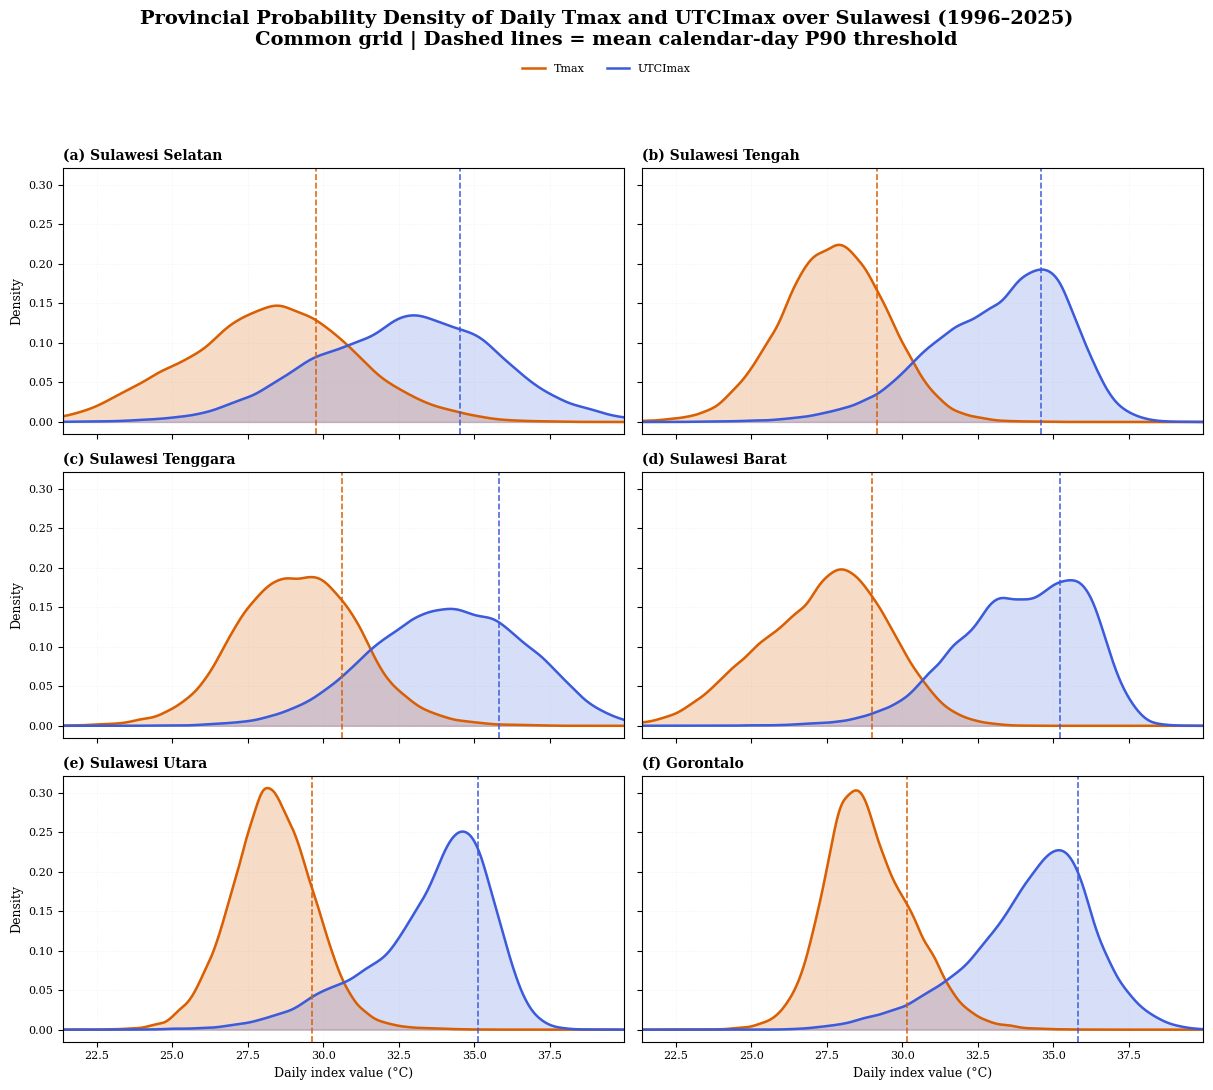

Saved: D:\MERLI\data\TMAX_UTCI_COMPARISON\Provincial_Journal_Integrated\plots\FIG01_Provincial_KDE_Absolute_Tmax_UTCImax_P90.png


In [31]:
# ============================================================
# FIGURE 1 — ABSOLUTE KDE BY PROVINCE
# ============================================================

fig, axes = plt.subplots(
    3,
    2,
    figsize=(
        12.2,
        11.0
    ),
    sharex=True,
    sharey=True,
)

panel_letters = [
    "a",
    "b",
    "c",
    "d",
    "e",
    "f",
]


for i, (
    ax,
    province
) in enumerate(
    zip(
        axes.flat,
        province_order
    )
):

    d = province_data[
        province
    ]

    y_t = kde_curve(
        d[
            "T_abs_kde"
        ],
        abs_xgrid,
    )

    y_u = kde_curve(
        d[
            "U_abs_kde"
        ],
        abs_xgrid,
    )


    # Tmax
    ax.plot(
        abs_xgrid,
        y_t,
        color=TMAX_COLOR,
        linewidth=1.8,
        label="Tmax",
    )

    ax.fill_between(
        abs_xgrid,
        0,
        y_t,
        color=TMAX_COLOR,
        alpha=0.22,
    )


    # UTCImax
    ax.plot(
        abs_xgrid,
        y_u,
        color=UTCI_COLOR,
        linewidth=1.8,
        label="UTCImax",
    )

    ax.fill_between(
        abs_xgrid,
        0,
        y_u,
        color=UTCI_COLOR,
        alpha=0.20,
    )


    # Mean calendar-day percentile threshold
    t_thr_mean = float(
        np.nanmean(
            d[
                "T_thr"
            ]
        )
    )

    u_thr_mean = float(
        np.nanmean(
            d[
                "U_thr"
            ]
        )
    )


    ax.axvline(
        t_thr_mean,
        color=TMAX_COLOR,
        linestyle="--",
        linewidth=1.15,
        alpha=0.95,
    )

    ax.axvline(
        u_thr_mean,
        color=UTCI_COLOR,
        linestyle="--",
        linewidth=1.15,
        alpha=0.95,
    )


    ax.set_title(
        f"({panel_letters[i]}) {province}",
        fontweight="bold",
        loc="left",
    )

    ax.grid(
        True,
        linestyle=":",
        linewidth=0.4,
        alpha=0.28,
    )

    ax.set_xlim(
        abs_xgrid.min(),
        abs_xgrid.max(),
    )


# Axis labels
for ax in axes[:, 0]:
    ax.set_ylabel(
        "Density"
    )

for ax in axes[-1, :]:
    ax.set_xlabel(
        "Daily index value (°C)"
    )


# Legend sekali saja
handles, labels = axes[0, 0].get_legend_handles_labels()

fig.legend(
    handles,
    labels,
    loc="upper center",
    ncol=2,
    frameon=False,
    bbox_to_anchor=(
        0.5,
        0.945
    ),
)

fig.suptitle(
    f"Provincial Probability Density of Daily Tmax and UTCImax over Sulawesi ({START_YEAR}–{END_YEAR})\n"
    f"Common grid | Dashed lines = mean calendar-day P{PERCENTILE} threshold",
    fontweight="bold",
    y=0.985,
)

fig.tight_layout(
    rect=[
        0,
        0,
        1,
        0.92
    ]
)


abs_png = (
    PLOT_DIR
    /
    f"FIG01_Provincial_KDE_Absolute_Tmax_UTCImax_P{PERCENTILE}.png"
)

fig.savefig(
    abs_png,
    dpi=FIG_DPI,
    bbox_inches="tight",
    facecolor="white",
)

if SAVE_PDF:
    fig.savefig(
        abs_png.with_suffix(
            ".pdf"
        ),
        bbox_inches="tight",
        facecolor="white",
    )

plt.show()
plt.close(
    fig
)

print(
    "Saved:",
    abs_png
)


# Figure 2 — Distribution relative to P90/P95 threshold

Ini adalah figure yang lebih adil untuk perbandingan heatwave karena masing-masing indeks dibandingkan dengan threshold lokal-hariannya sendiri:

\[
X - P_x
\]

- `x < 0` = di bawah threshold
- `x = 0` = tepat threshold
- `x > 0` = melebihi threshold

Angka kecil di panel menunjukkan persentase observasi harian yang berada di atas threshold sebelum syarat durasi heatwave diterapkan.


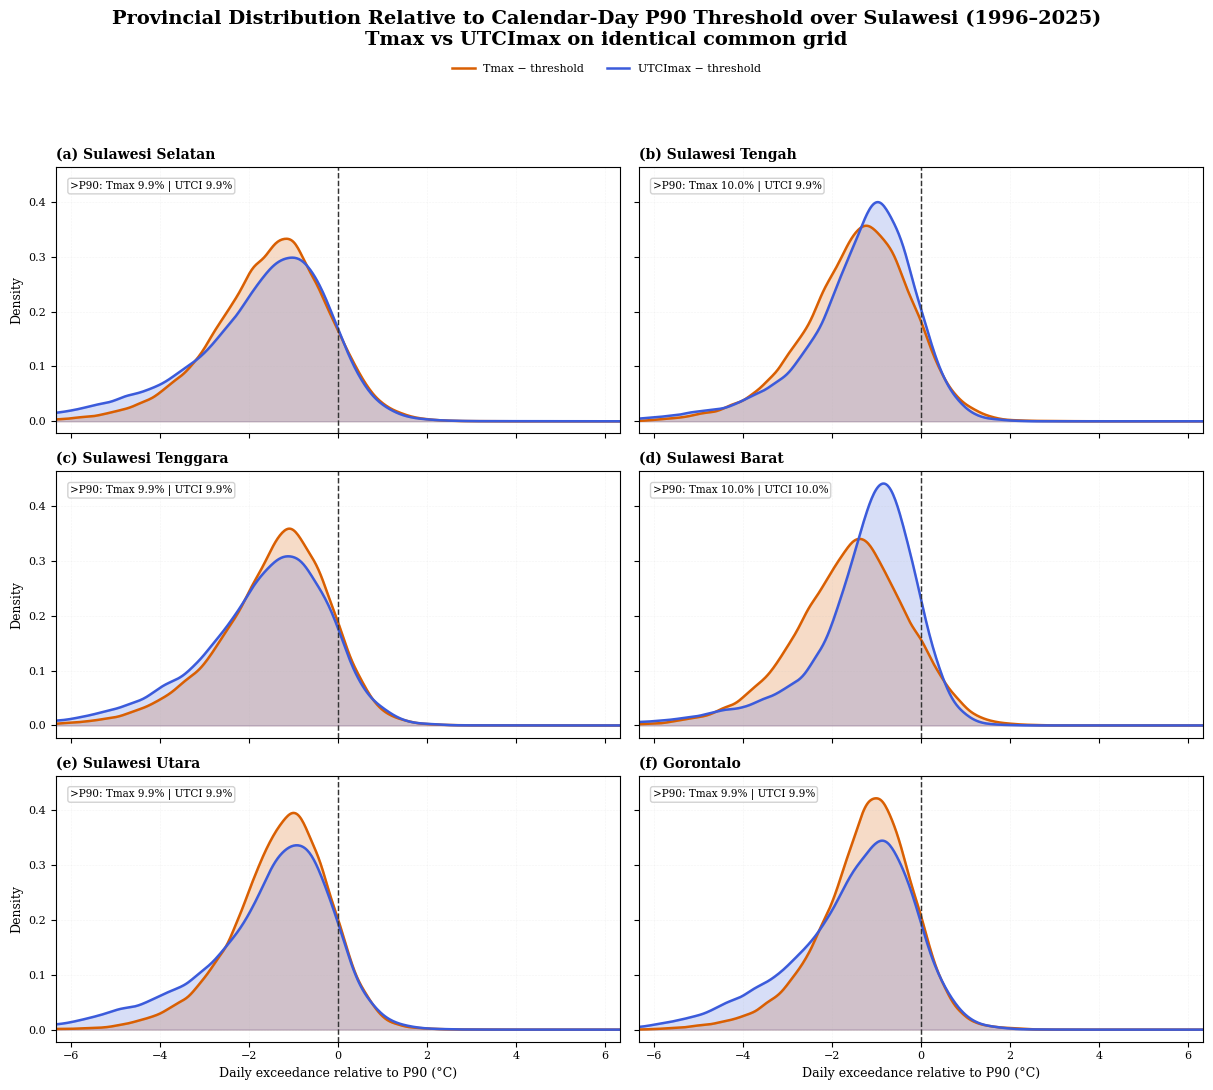

Saved: D:\MERLI\data\TMAX_UTCI_COMPARISON\Provincial_Journal_Integrated\plots\FIG02_Provincial_KDE_ThresholdRelative_Tmax_UTCImax_P90.png


In [32]:
# ============================================================
# FIGURE 2 — THRESHOLD-RELATIVE KDE BY PROVINCE
# ============================================================

fig, axes = plt.subplots(
    3,
    2,
    figsize=(
        12.2,
        11.0
    ),
    sharex=True,
    sharey=True,
)


for i, (
    ax,
    province
) in enumerate(
    zip(
        axes.flat,
        province_order
    )
):

    d = province_data[
        province
    ]

    y_t = kde_curve(
        d[
            "T_exc_kde"
        ],
        exc_xgrid,
    )

    y_u = kde_curve(
        d[
            "U_exc_kde"
        ],
        exc_xgrid,
    )


    ax.plot(
        exc_xgrid,
        y_t,
        color=TMAX_COLOR,
        linewidth=1.8,
        label="Tmax − threshold",
    )

    ax.fill_between(
        exc_xgrid,
        0,
        y_t,
        color=TMAX_COLOR,
        alpha=0.22,
    )


    ax.plot(
        exc_xgrid,
        y_u,
        color=UTCI_COLOR,
        linewidth=1.8,
        label="UTCImax − threshold",
    )

    ax.fill_between(
        exc_xgrid,
        0,
        y_u,
        color=UTCI_COLOR,
        alpha=0.20,
    )


    # Threshold boundary
    ax.axvline(
        0,
        color="0.20",
        linestyle="--",
        linewidth=1.05,
    )


    t_pct = (
        100.0
        *
        np.mean(
            d[
                "T_exc"
            ]
            > 0
        )
    )

    u_pct = (
        100.0
        *
        np.mean(
            d[
                "U_exc"
            ]
            > 0
        )
    )


    ax.text(
        0.025,
        0.95,
        (
            f">P{PERCENTILE}: "
            f"Tmax {t_pct:.1f}% | "
            f"UTCI {u_pct:.1f}%"
        ),
        transform=ax.transAxes,
        ha="left",
        va="top",
        fontsize=7.5,
        bbox=dict(
            boxstyle="round,pad=0.22",
            facecolor="white",
            edgecolor="0.80",
            alpha=0.88,
        ),
    )


    ax.set_title(
        f"({panel_letters[i]}) {province}",
        fontweight="bold",
        loc="left",
    )

    ax.grid(
        True,
        linestyle=":",
        linewidth=0.4,
        alpha=0.28,
    )

    ax.set_xlim(
        exc_xgrid.min(),
        exc_xgrid.max(),
    )


for ax in axes[:, 0]:
    ax.set_ylabel(
        "Density"
    )

for ax in axes[-1, :]:
    ax.set_xlabel(
        f"Daily exceedance relative to P{PERCENTILE} (°C)"
    )


handles, labels = (
    axes[0, 0]
    .get_legend_handles_labels()
)

fig.legend(
    handles,
    labels,
    loc="upper center",
    ncol=2,
    frameon=False,
    bbox_to_anchor=(
        0.5,
        0.945
    ),
)


fig.suptitle(
    f"Provincial Distribution Relative to Calendar-Day P{PERCENTILE} Threshold over Sulawesi ({START_YEAR}–{END_YEAR})\n"
    f"Tmax vs UTCImax on identical common grid",
    fontweight="bold",
    y=0.985,
)


fig.tight_layout(
    rect=[
        0,
        0,
        1,
        0.92
    ]
)


exc_png = (
    PLOT_DIR
    /
    f"FIG02_Provincial_KDE_ThresholdRelative_Tmax_UTCImax_P{PERCENTILE}.png"
)

fig.savefig(
    exc_png,
    dpi=FIG_DPI,
    bbox_inches="tight",
    facecolor="white",
)

if SAVE_PDF:
    fig.savefig(
        exc_png.with_suffix(
            ".pdf"
        ),
        bbox_inches="tight",
        facecolor="white",
    )


plt.show()
plt.close(
    fig
)

print(
    "Saved:",
    exc_png
)


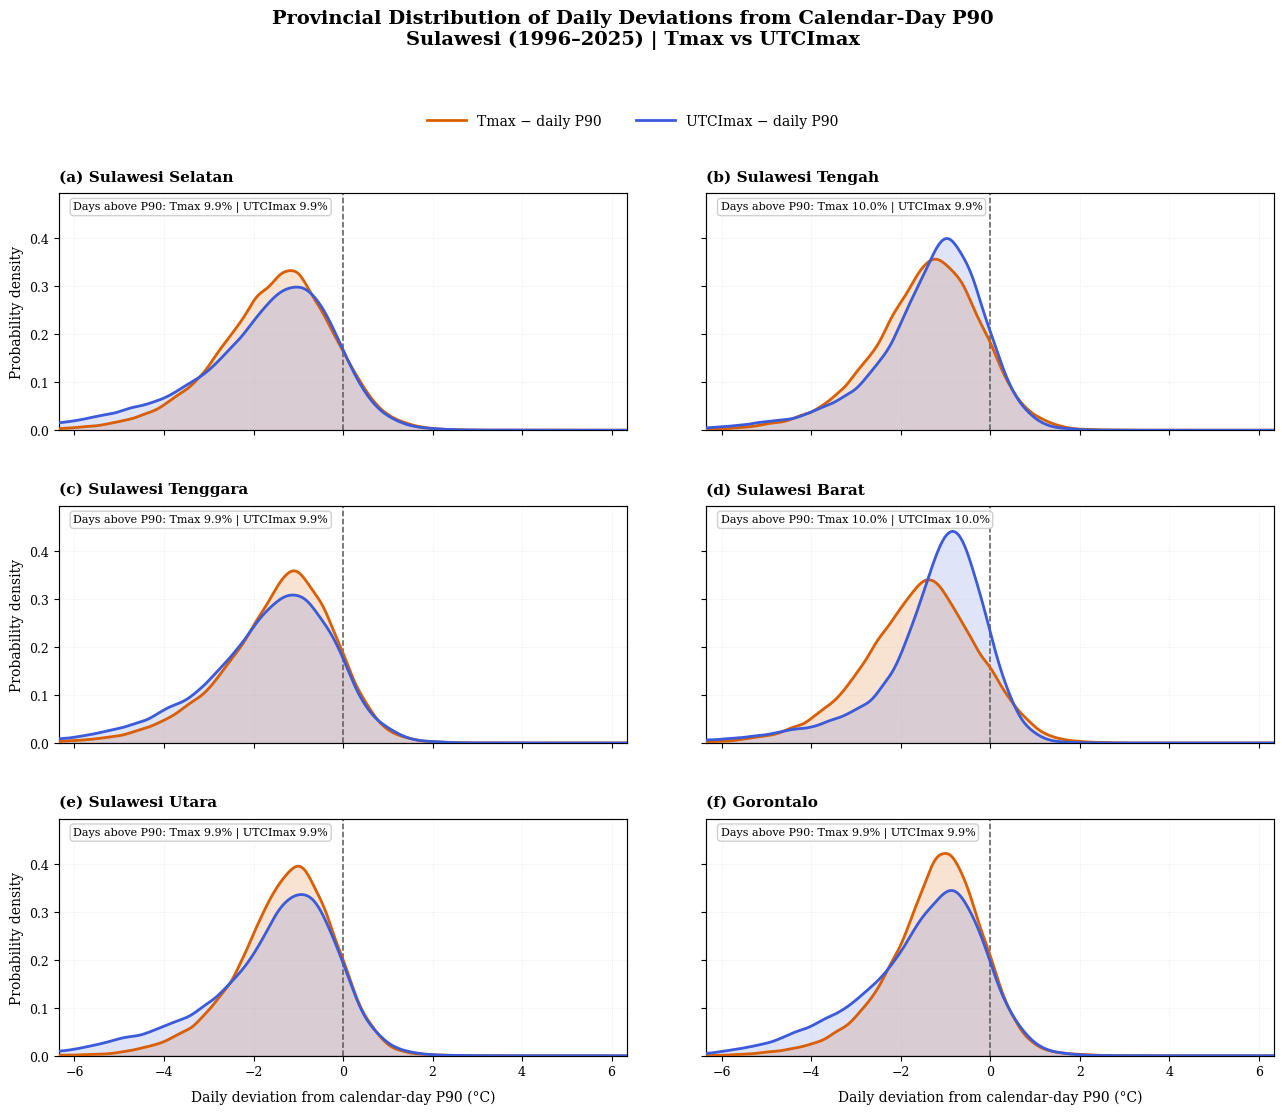

Figure saved: D:\MERLI\data\TMAX_UTCI_COMPARISON\Provincial_Journal_Integrated\plots\FIG02_Provincial_KDE_ThresholdRelative_Tmax_UTCImax_P90.png


In [33]:
# ============================================================
# FIGURE 2 — PROVINCIAL DAILY DEVIATION KDE (FIXED Y-LIMIT)
# ============================================================

fig, axes = plt.subplots(
    3, 2,
    figsize=(13.5, 11.5),
    sharex=True,
    sharey=True
)

fig.subplots_adjust(
    left=0.075,
    right=0.975,
    bottom=0.075,
    top=0.825,
    hspace=0.32,
    wspace=0.14
)

# ------------------------------------------------------------
# PRECOMPUTE KDE + GLOBAL Y MAX
# ------------------------------------------------------------
kde_store = {}
global_ymax = 0.0

for province in province_order:
    d = province_data[province]

    y_t = kde_curve(
        d["T_exc_kde"],
        exc_xgrid
    )
    y_u = kde_curve(
        d["U_exc_kde"],
        exc_xgrid
    )

    kde_store[province] = {
        "y_t": y_t,
        "y_u": y_u,
        "T_exc": np.asarray(d["T_exc"]),
        "U_exc": np.asarray(d["U_exc"]),
    }

    local_max = np.nanmax([np.nanmax(y_t), np.nanmax(y_u)])
    if local_max > global_ymax:
        global_ymax = local_max

# kasih ruang di atas biar gak mentok
global_ymax = global_ymax * 1.12

# ------------------------------------------------------------
# PLOT
# ------------------------------------------------------------
for i, (ax, province) in enumerate(zip(axes.flat, province_order)):

    y_t = kde_store[province]["y_t"]
    y_u = kde_store[province]["y_u"]
    t_values = kde_store[province]["T_exc"]
    u_values = kde_store[province]["U_exc"]

    # Tmax
    ax.plot(
        exc_xgrid,
        y_t,
        color=TMAX_COLOR,
        linewidth=2.0,
        label=f"Tmax − daily P{PERCENTILE}",
        zorder=3
    )
    ax.fill_between(
        exc_xgrid,
        0,
        y_t,
        color=TMAX_COLOR,
        alpha=0.18
    )

    # UTCImax
    ax.plot(
        exc_xgrid,
        y_u,
        color=UTCI_COLOR,
        linewidth=2.0,
        label=f"UTCImax − daily P{PERCENTILE}",
        zorder=3
    )
    ax.fill_between(
        exc_xgrid,
        0,
        y_u,
        color=UTCI_COLOR,
        alpha=0.16
    )

    # garis ambang
    ax.axvline(
        x=0,
        color="0.35",
        linestyle="--",
        linewidth=1.1,
        zorder=2
    )

    # % hari di atas ambang harian P90
    t_valid = t_values[np.isfinite(t_values)]
    u_valid = u_values[np.isfinite(u_values)]

    t_pct = 100 * np.mean(t_valid > 0) if t_valid.size > 0 else np.nan
    u_pct = 100 * np.mean(u_valid > 0) if u_valid.size > 0 else np.nan

    ax.text(
        0.025,
        0.965,
        (
            f"Days above P{PERCENTILE}: "
            f"Tmax {t_pct:.1f}% | UTCImax {u_pct:.1f}%"
        ),
        transform=ax.transAxes,
        ha="left",
        va="top",
        fontsize=8.0,
        bbox=dict(
            boxstyle="round,pad=0.28",
            facecolor="white",
            edgecolor="0.80",
            alpha=0.92
        ),
        zorder=5
    )

    ax.set_title(
        f"({panel_letters[i]}) {province}",
        loc="left",
        fontsize=11,
        fontweight="bold",
        pad=9
    )

    ax.grid(
        True,
        linestyle=":",
        linewidth=0.55,
        alpha=0.28,
        zorder=0
    )

    ax.set_xlim(exc_xgrid.min(), exc_xgrid.max())
    ax.set_ylim(0, global_ymax)

    ax.tick_params(
        axis="both",
        labelsize=9
    )

    for spine in ax.spines.values():
        spine.set_linewidth(0.85)

# ------------------------------------------------------------
# LABEL AXIS
# ------------------------------------------------------------
for ax in axes[:, 0]:
    ax.set_ylabel(
        "Probability density",
        fontsize=10
    )

for ax in axes[-1, :]:
    ax.set_xlabel(
        f"Daily deviation from calendar-day P{PERCENTILE} (°C)",
        fontsize=10,
        labelpad=8
    )

# ------------------------------------------------------------
# JUDUL & LEGENDA
# ------------------------------------------------------------
fig.suptitle(
    "Provincial Distribution of Daily Deviations from Calendar-Day "
    f"P{PERCENTILE}\n"
    f"Sulawesi ({START_YEAR}–{END_YEAR}) | Tmax vs UTCImax",
    fontsize=14,
    fontweight="bold",
    y=0.985
)

handles, labels = axes[0, 0].get_legend_handles_labels()

fig.legend(
    handles,
    labels,
    loc="upper center",
    bbox_to_anchor=(0.5, 0.905),
    ncol=2,
    frameon=False,
    fontsize=10,
    handlelength=2.8,
    columnspacing=2.5
)

# ------------------------------------------------------------
# SAVE
# ------------------------------------------------------------
exc_png = (
    PLOT_DIR /
    f"FIG02_Provincial_KDE_ThresholdRelative_Tmax_UTCImax_P{PERCENTILE}.png"
)

fig.savefig(
    exc_png,
    dpi=FIG_DPI,
    bbox_inches="tight",
    facecolor="white"
)

if SAVE_PDF:
    fig.savefig(
        exc_png.with_suffix(".pdf"),
        bbox_inches="tight",
        facecolor="white"
    )

plt.show()
plt.close(fig)

print("Figure saved:", exc_png)

## QC wajib sebelum membuat interpretasi
Sumber KDE memang membandingkan tanggal dan grid yang sama. Grafik indeks tahunan di bawah menggunakan **metriks tahunan dari masing-masing pipeline sumber**, diseleksi ke **grid pusat bersama yang masuk ke enam provinsi**. Ketika validitas data harian antarindikator berbeda, hasilnya perlu ditafsirkan hati-hati. Sel berikut mencetak jumlah grid dan persentase kelengkapan. Jangan lanjut jika koordinat, grid, atau kelengkapan tidak masuk akal.

In [34]:
# QC provinsi, overlap mask, dan kelengkapan harian
mask_stack = np.stack([province_masks[p] for p in province_order], axis=0)
if np.any(mask_stack.sum(axis=0) > 1):
    raise ValueError("Satu grid masuk lebih dari satu provinsi; periksa geometri Natural Earth.")
province_union_mask = mask_stack.any(axis=0)
if not np.any(province_union_mask):
    raise ValueError("Mask provinsi kosong. Periksa nama dan koordinat grid.")
for p in province_order:
    if province_masks[p].sum() < 4:
        raise ValueError(f"{p} punya kurang dari 4 pusat grid; cek masking/province aliases: {province_masks[p].sum()}")
qc_rows = []
for p in province_order:
    m = province_masks[p]
    n_total = int(len(tmax_dates) * m.sum())
    paired = (np.isfinite(tmax_values_cmp[:, m]) & np.isfinite(utci_values_cmp[:, m]))
    qc_rows.append({
        'province': p, 'common_grid_count': int(m.sum()),
        'tmax_valid_pct': float(np.isfinite(tmax_values_cmp[:, m]).sum()*100/n_total),
        'utci_valid_pct': float(np.isfinite(utci_values_cmp[:, m]).sum()*100/n_total),
        'paired_valid_pct': float(paired.sum()*100/n_total),
    })
coverage_df = pd.DataFrame(qc_rows)
display(coverage_df.round(2))
coverage_df.to_csv(TABLE_DIR/'TABLE00_Coverage_By_Province.csv', index=False)
if (coverage_df.paired_valid_pct < 90).any():
    print('PERINGATAN: Ada provinsi dengan kurang dari 90% data paired valid. Interpretasi perbandingan harus hati-hati.')
assert len(tmax_dates) == len(utci_dates)
assert tmax_thr_cal.shape[0] == 365 and utci_thr_cal.shape[0] == 365

,province,common_grid_count,tmax_valid_pct,utci_valid_pct,paired_valid_pct
0,Sulawesi Selatan,65,100.0,100.0,100.0
1,Sulawesi Tengah,77,100.0,100.0,100.0
2,Sulawesi Tenggara,43,100.0,100.0,100.0
3,Sulawesi Barat,21,100.0,100.0,100.0
4,Sulawesi Utara,19,100.0,100.0,100.0
5,Gorontalo,17,100.0,100.0,100.0


## 3. Baca hasil tahunan dari notebook Tmax dan UTCI (P90-D3 / P95-D3)
**Tidak mengulang deteksi heatwave dengan algoritme baru.** Notebook gabungan ini mengambil keluaran **HWN, HWF, HWD, HWA_abs, HWM_abs** dari workflow sumber yang sudah berjalan, agar hasilnya konsisten. Untuk setiap provinsi, rerata antar-grid ditimbang dengan kosinus lintang. Intensitas HWA/HWM yang `NaN` karena tidak ada episode **tidak diganti nol**.

In [35]:
# Load metric yearly cache; coordinate Tmax sorted ascending and subset to UTCI native grid.
tcache = np.load(TMAX_METRIC_CACHE)
udy = xr.open_dataset(UTCI_METRICS_FILE, engine='netcdf4', decode_timedelta=False)
if 'year' not in udy.dims:
    raise ValueError('Variabel year tidak tersedia di metrics UTCI.')
if (PERCENTILE not in udy['percentile'].values or
        MIN_DURATION not in udy['min_duration'].values):
    raise ValueError(f'Skenario {MAIN_SCENARIO} tidak tersedia dalam UTCI metrics.')
YEARS = np.arange(START_YEAR, END_YEAR + 1, dtype=int)
if 'years' in tcache and not np.array_equal(tcache['years'], YEARS):
    raise ValueError('Tahun dalam metrics Tmax berbeda dengan 1996–2025.')
if not np.array_equal(udy['year'].values, YEARS):
    raise ValueError('Tahun dalam metrics UTCI berbeda dengan 1996–2025.')
# Pastikan koordinat UTCI annual dan daily benar-benar identik
if not (np.allclose(udy['latitude'].values, cmp_lat, atol=GRID_TOL, rtol=0)
        and np.allclose(udy['longitude'].values, cmp_lon, atol=GRID_TOL, rtol=0)):
    raise ValueError('Grid UTCI annual vs daily tidak cocok; jangan lanjut.')

annual_fields = {'Tmax': {}, 'UTCImax': {}}
for metric, key in METRIC_KEYS.items():
    if key not in tcache.files or key not in udy.data_vars:
        raise KeyError(f'Metrik {key} tidak tersedia pada salah satu workflow.')
    ta = np.asarray(tcache[key], dtype=np.float32)
    t_aligned = np.take(np.take(ta, tmax_lat_idx, axis=1), tmax_lon_idx, axis=2)
    ua = np.asarray(udy[key].sel(percentile=PERCENTILE, min_duration=MIN_DURATION).transpose('year','latitude','longitude').values, dtype=np.float32)
    if t_aligned.shape != ua.shape or t_aligned.shape != (len(YEARS), len(cmp_lat), len(cmp_lon)):
        raise ValueError(f'Metric alignment mismatch: {key}, {t_aligned.shape} vs {ua.shape}')
    annual_fields['Tmax'][metric] = np.where(province_union_mask[None], t_aligned, np.nan)
    annual_fields['UTCImax'][metric] = np.where(province_union_mask[None], ua, np.nan)

# Regional statistics only at valid same province grid centres.
weights2d = np.broadcast_to(np.cos(np.deg2rad(cmp_lat))[:, None], province_union_mask.shape)
def weighted_mean_grids(arr, province_mask):
    z = np.asarray(arr, dtype=float)
    w = np.where(province_mask, weights2d, 0.)
    valid = np.isfinite(z) & (w[None] > 0)
    den = np.sum(np.where(valid, w[None], 0.0), axis=(1, 2))
    num = np.sum(np.where(valid, z * w[None], 0.0), axis=(1, 2))
    return np.divide(num, den, out=np.full(z.shape[0], np.nan), where=den > 0)

rows = []
for prov in province_order:
    for basis in ['Tmax','UTCImax']:
        for metric in METRIC_CODES:
            values = weighted_mean_grids(annual_fields[basis][metric], province_masks[prov])
            for year, v in zip(YEARS, values):
                rows.append({'province':prov, 'basis':basis, 'metric':metric, 'year':int(year),
                             'value':float(v)})
prov_annual = pd.DataFrame(rows)
prov_annual.to_csv(TABLE_DIR/f'TABLE01_Annual_Province_Metrics_{MAIN_SCENARIO}.csv', index=False)
display(prov_annual.head(12))
print('Annual rows:', len(prov_annual), ' expected:',6*2*5*30)

,province,basis,metric,year,value
0,Sulawesi Selatan,Tmax,HWN,1996,0.153579
1,Sulawesi Selatan,Tmax,HWN,1997,1.446054
2,Sulawesi Selatan,Tmax,HWN,1998,1.981973
3,Sulawesi Selatan,Tmax,HWN,1999,0.030731
4,Sulawesi Selatan,Tmax,HWN,2000,0.569200
5,Sulawesi Selatan,Tmax,HWN,2001,0.307460
6,Sulawesi Selatan,Tmax,HWN,2002,1.491475
7,Sulawesi Selatan,Tmax,HWN,2003,0.307515
8,Sulawesi Selatan,Tmax,HWN,2004,1.461143
9,Sulawesi Selatan,Tmax,HWN,2005,2.967125


Annual rows: 1800  expected: 1800


## 4. Tabel hasil dan analisis tren per provinsi
Tren memakai **Theil–Sen (satuan per dekade)** dan `kendalltau` (p dua sisi). Simpangan antar-tahun bukan ketidakpastian model reanalisis. Peringatan: tanpa koreksi autokorelasi atau *multiple testing*, nilai p tidak boleh dipakai untuk klaim kausalitas.

In [36]:
trend_rows = []
for (prov, basis, metric), sub in prov_annual.groupby(['province','basis','metric'], sort=False):
    x = sub.year.to_numpy(dtype=float)
    y = sub.value.to_numpy(dtype=float)
    valid = np.isfinite(y)
    if valid.sum() >= 8 and np.nanstd(y[valid]) > 0:
        slope, intercept, lo, hi = theilslopes(y[valid], x[valid], alpha=0.95)
        tau, pv = kendalltau(x[valid], y[valid])
        slope, lo, hi = 10*slope, 10*lo, 10*hi
    else:
        slope=lo=hi=tau=pv=np.nan
    trend_rows.append({'province':prov,'basis':basis,'metric':metric,'n_years':int(valid.sum()),
        'mean_1996_2025':float(np.nanmean(y)) if valid.any() else np.nan,
        'sd_annual':float(np.nanstd(y, ddof=1)) if valid.sum()>1 else np.nan,
        'slope_decade':slope,'slope_ci_low':lo,'slope_ci_high':hi,
        'kendall_tau':tau,'kendall_p':pv,'significant_0_05':bool(np.isfinite(pv) and pv < 0.05)})
trend_df = pd.DataFrame(trend_rows)
trend_df.to_csv(TABLE_DIR/f'TABLE02_Provincial_TheilSen_Kendall_{MAIN_SCENARIO}.csv', index=False)
display(trend_df.round(3))
# Correlation between two indicators' annual series within each province and metric.
corr_rows=[]
for prov in province_order:
    for metric in METRIC_CODES:
        a=prov_annual.query('province == @prov and basis == "Tmax" and metric == @metric').sort_values('year').value.to_numpy()
        b=prov_annual.query('province == @prov and basis == "UTCImax" and metric == @metric').sort_values('year').value.to_numpy()
        v=np.isfinite(a)&np.isfinite(b)
        r, p = pearsonr(a[v],b[v]) if v.sum()>=3 and np.std(a[v])>0 and np.std(b[v])>0 else (np.nan,np.nan)
        corr_rows.append({'province':prov,'metric':metric,'paired_years':int(v.sum()),'pearson_r':r,'pearson_p':p})
corr_df=pd.DataFrame(corr_rows)
corr_df.to_csv(TABLE_DIR/f'TABLE03_Annual_Correlations_{MAIN_SCENARIO}.csv', index=False)

,province,basis,metric,n_years,mean_1996_2025,sd_annual,slope_decade,slope_ci_low,slope_ci_high,kendall_tau,kendall_p,significant_0_05
0,Sulawesi Selatan,Tmax,HWN,30,3.327,3.647,2.509,1.525,3.849,0.559,0.000,True
1,Sulawesi Selatan,Tmax,HWF,30,14.467,17.107,10.185,5.789,16.359,0.540,0.000,True
2,Sulawesi Selatan,Tmax,HWD,30,4.080,3.211,2.371,1.583,3.369,0.540,0.000,True
3,Sulawesi Selatan,Tmax,HWA,30,31.847,1.166,0.310,-0.205,0.717,0.182,0.165,False
4,Sulawesi Selatan,Tmax,HWM,30,30.771,1.081,-0.201,-0.587,0.152,-0.163,0.214,False
5,Sulawesi Selatan,UTCImax,HWN,30,2.598,2.195,0.847,0.254,1.490,0.379,0.003,True
6,Sulawesi Selatan,UTCImax,HWF,30,10.387,9.542,3.639,0.969,5.698,0.347,0.007,True
7,Sulawesi Selatan,UTCImax,HWD,30,3.832,1.907,0.963,0.156,1.644,0.310,0.016,True
8,Sulawesi Selatan,UTCImax,HWA,30,36.179,0.681,0.319,0.026,0.623,0.269,0.038,True
9,Sulawesi Selatan,UTCImax,HWM,30,35.109,0.536,0.212,-0.030,0.400,0.232,0.074,False


## Figure 3 — Perbandingan nilai klimatologis lima karakteristik antarprovinsi
Panel terpisah agar satuan tidak tercampur. Grafik memperlihatkan rerata **1996–2025** per provinsi untuk definisi yang sama, tanpa membuat rata-rata UTCI dianggap temperatur udara.

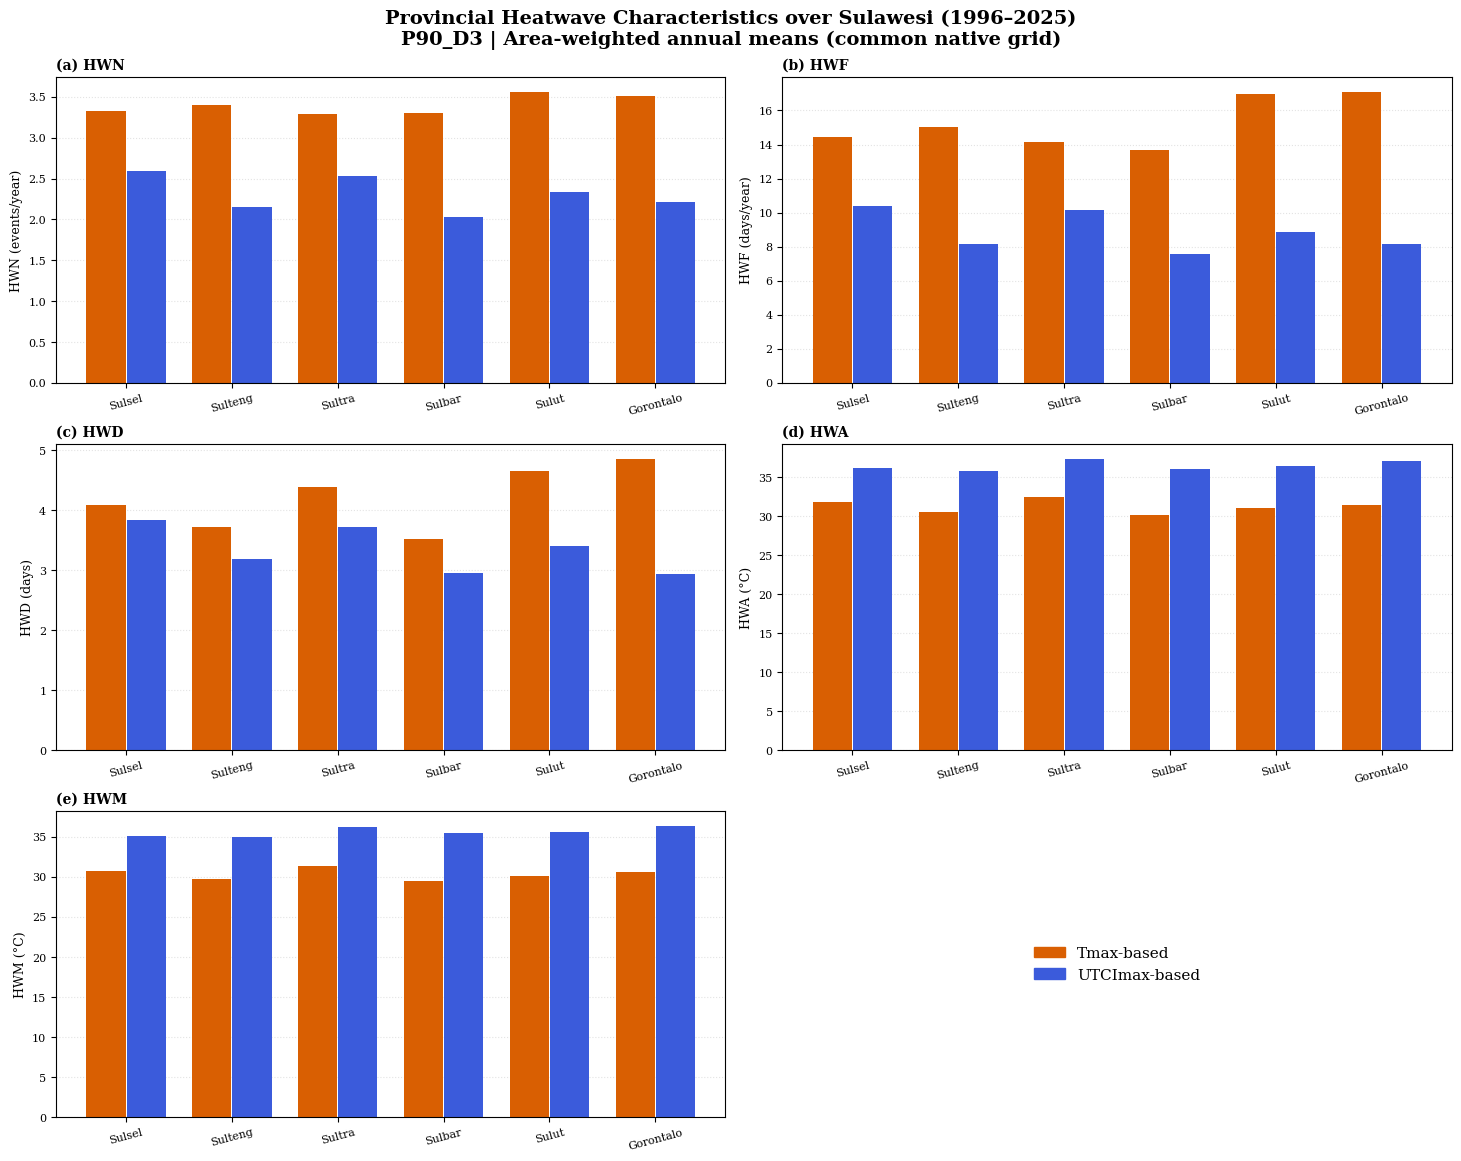

D:\MERLI\data\TMAX_UTCI_COMPARISON\Provincial_Journal_Integrated\plots\FIG03_Provincial_Climatology_Five_Metrics_P90_D3.png


In [37]:
from matplotlib.patches import Patch
fig, axs = plt.subplots(3, 2, figsize=(14.5, 11.5), constrained_layout=True)
for i, metric in enumerate(METRIC_CODES):
    ax=axs.flat[i]
    td=trend_df[trend_df.metric.eq(metric)].set_index(['province','basis'])
    xt=np.arange(len(province_order))
    tv=np.array([td.loc[(p,'Tmax'),'mean_1996_2025'] for p in province_order])
    uv=np.array([td.loc[(p,'UTCImax'),'mean_1996_2025'] for p in province_order])
    ax.bar(xt-.19,tv,width=.37,color=TMAX_COLOR,label='Tmax-based')
    ax.bar(xt+.19,uv,width=.37,color=UTCI_COLOR,label='UTCImax-based')
    ax.set_xticks(xt, [province_short[p] for p in province_order], rotation=15)
    ax.set_ylabel(f'{metric} ({METRIC_UNIT[metric]})')
    ax.set_title(f'({chr(97+i)}) {metric}',loc='left',fontweight='bold')
    ax.grid(axis='y',ls=':',alpha=.35)
    ax.set_axisbelow(True)
axs.flat[-1].axis('off')
axs.flat[-1].legend(handles=[Patch(color=TMAX_COLOR,label='Tmax-based'),Patch(color=UTCI_COLOR,label='UTCImax-based')],loc='center',frameon=False,fontsize=11)
fig.suptitle(f'Provincial Heatwave Characteristics over Sulawesi ({START_YEAR}–{END_YEAR})\n{MAIN_SCENARIO} | Area-weighted annual means (common native grid)', fontsize=14,weight='bold')
out=PLOT_DIR/f'FIG03_Provincial_Climatology_Five_Metrics_{MAIN_SCENARIO}.png'
fig.savefig(out,dpi=FIG_DPI,bbox_inches='tight')
if SAVE_PDF: fig.savefig(out.with_suffix('.pdf'),bbox_inches='tight')
plt.show();plt.close(fig)
print(out)

## Figures 4a–4e — Grafik enam provinsi untuk setiap indeks (1996–2025)
**Setiap indeks satu figure 3×2** agar keterbacaan tetap baik. Garis tipis = nilai tahunan; garis tebal = rerata bergerak 5 tahun; garis putus-putus = estimasi tren Theil–Sen. Label slope per dekade ditampilkan pada panel dengan p Kendall (tanpa menyamakan besar HWA/HWM Tmax dan UTCI sebagai suhu fisik identik).

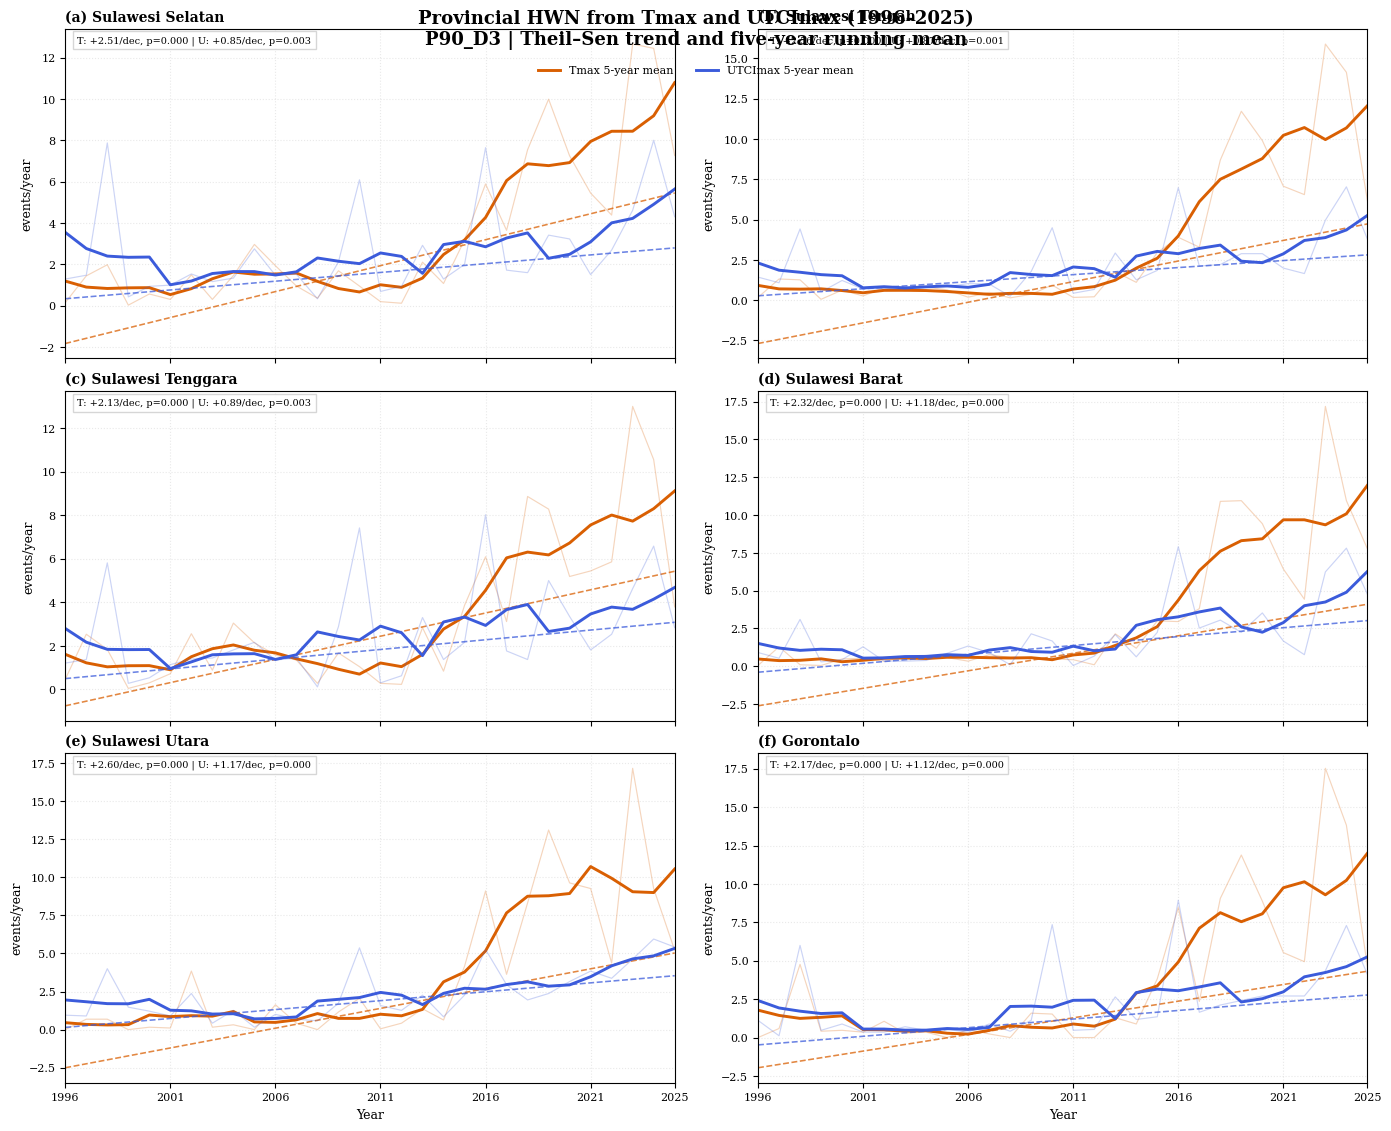

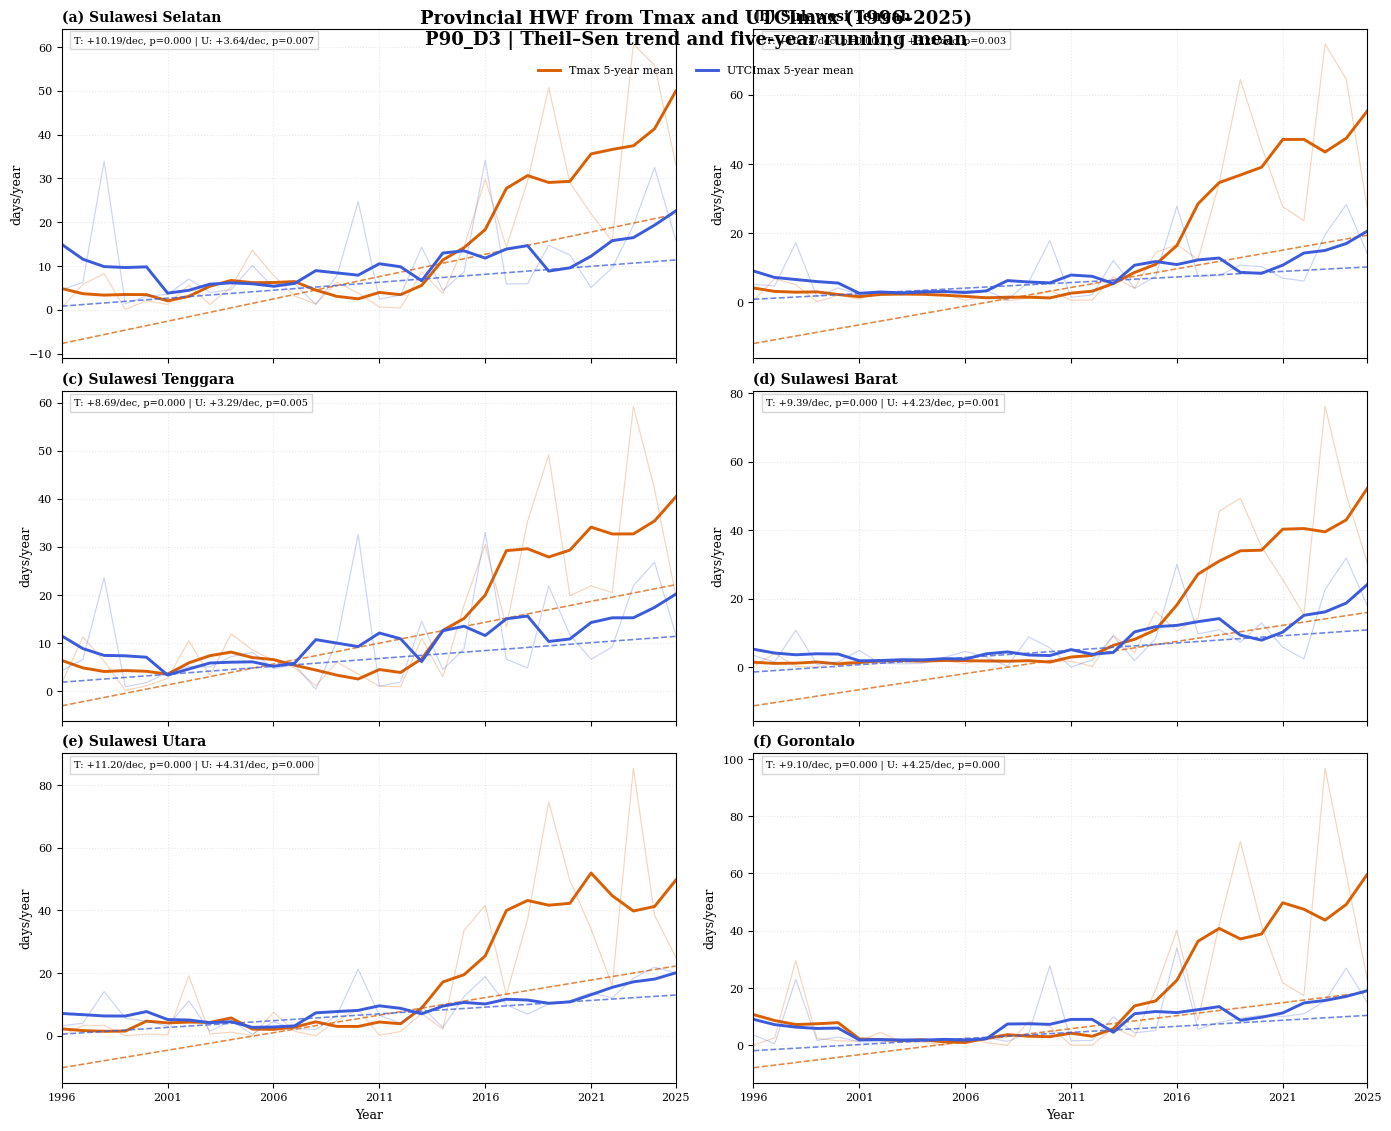

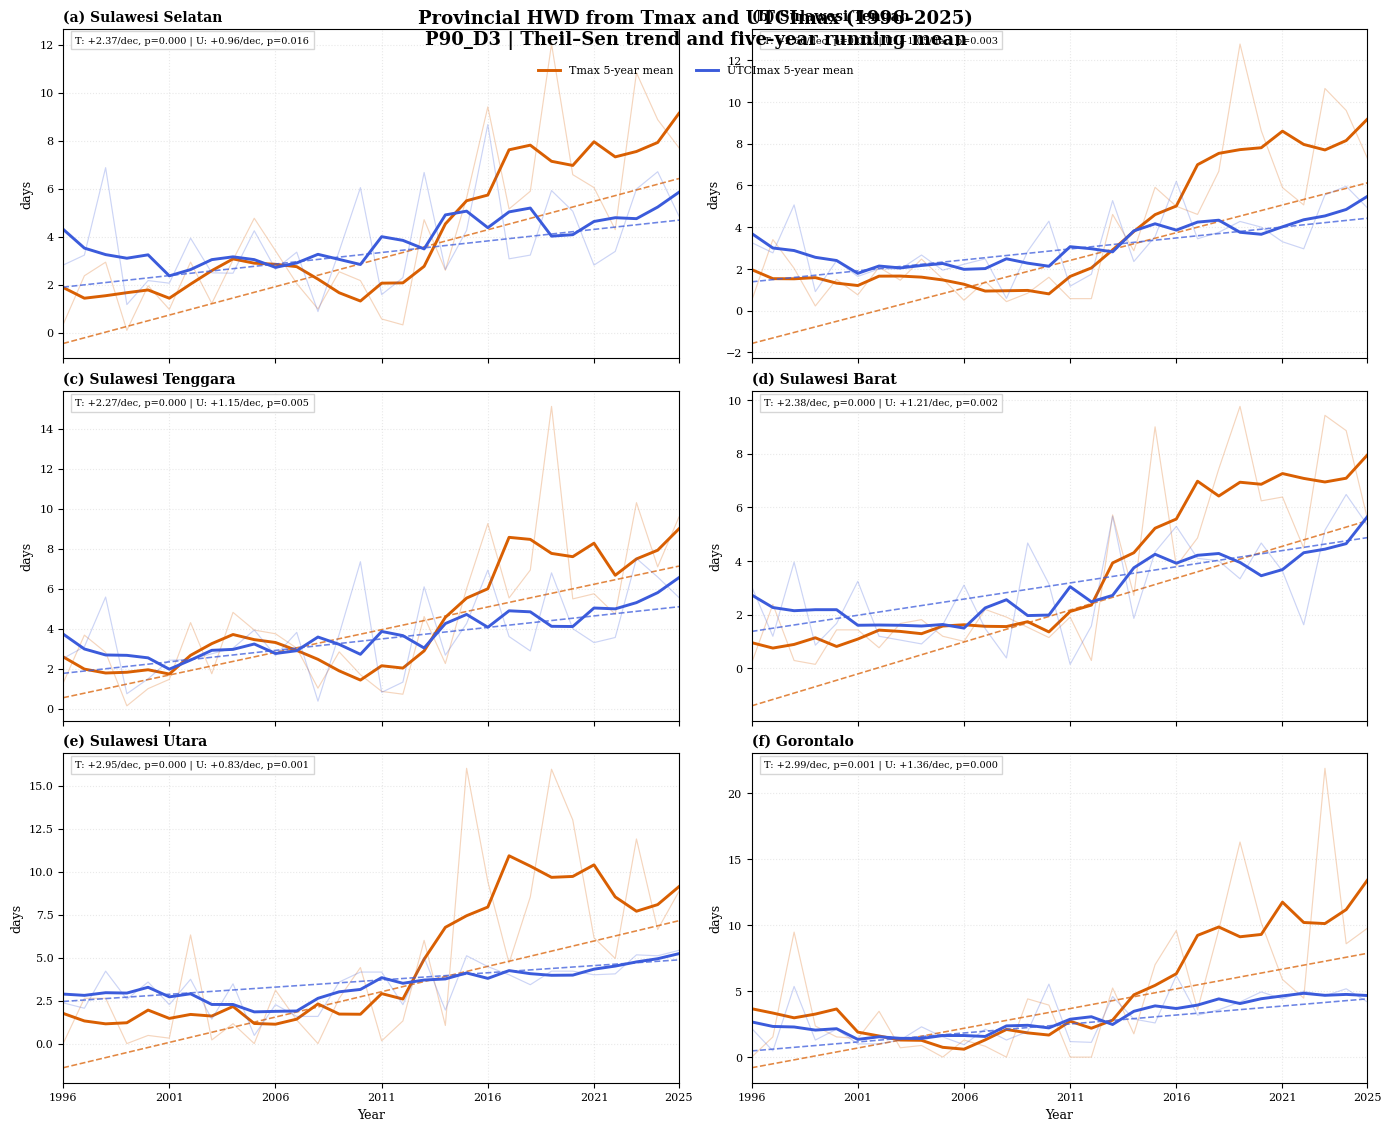

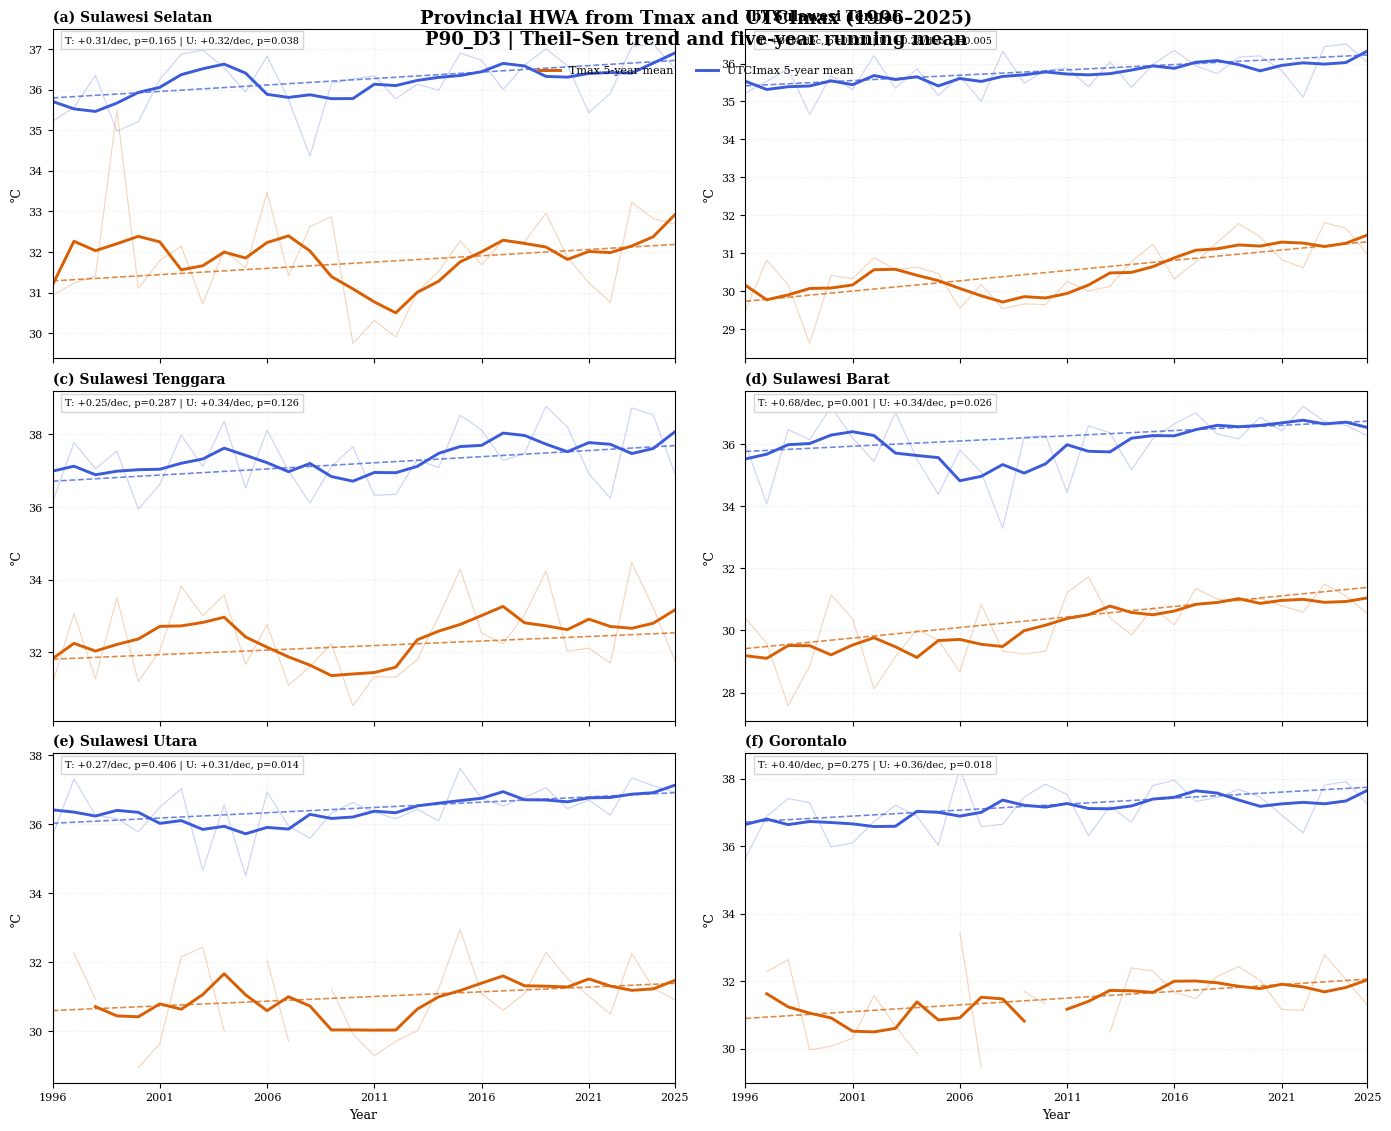

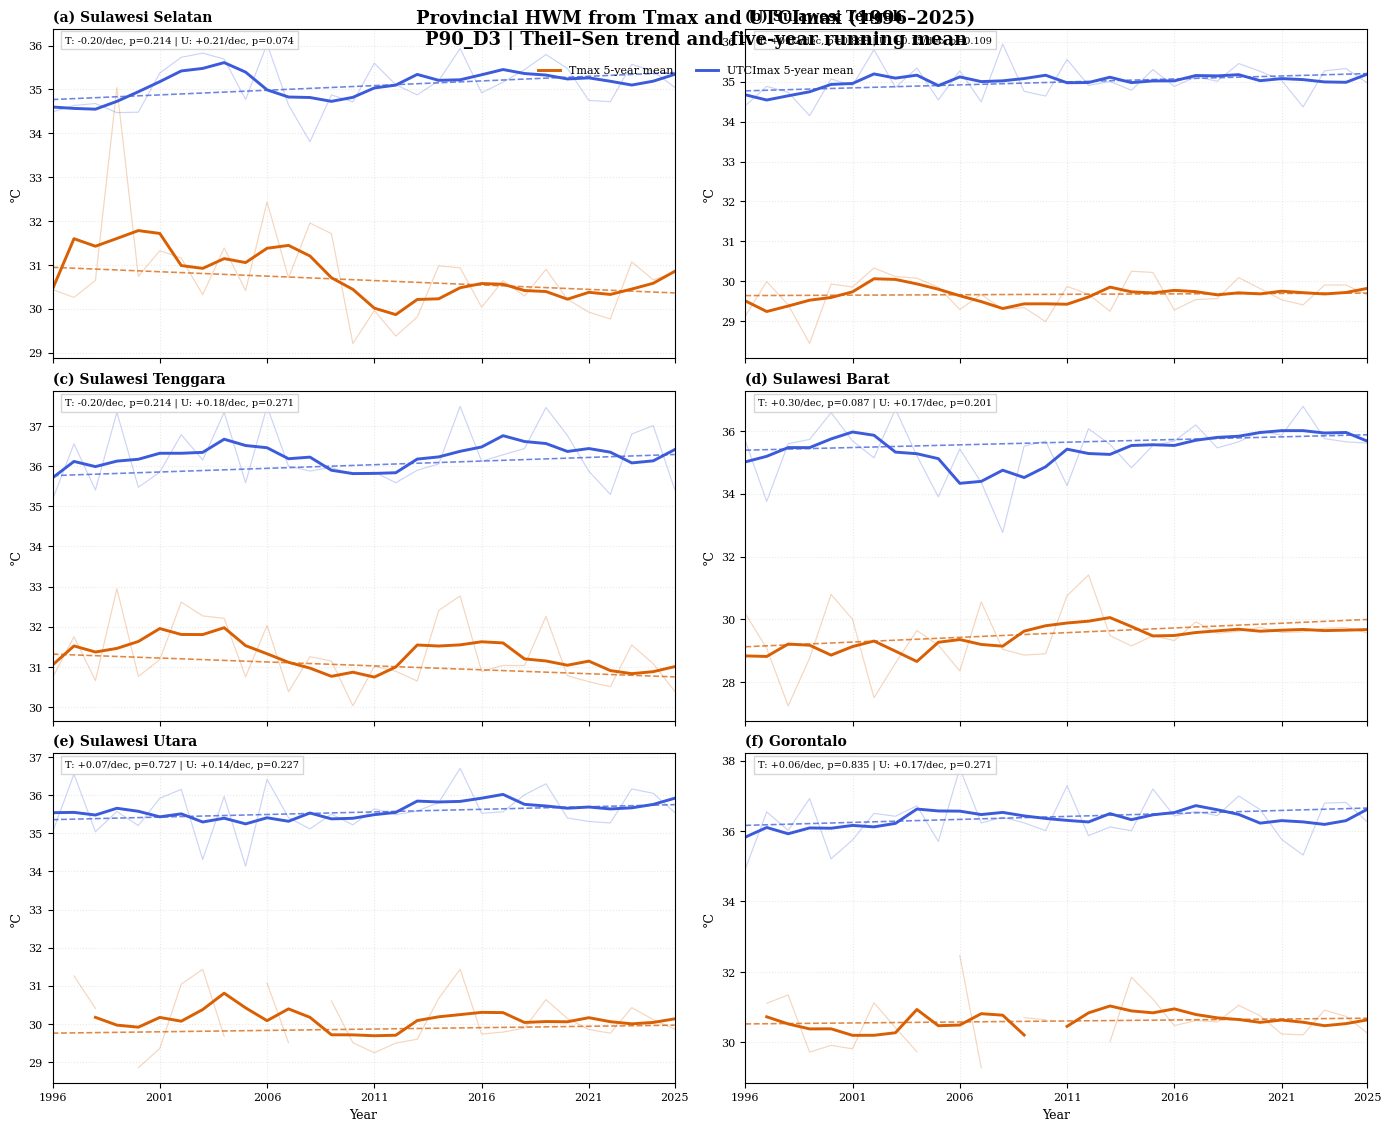

In [38]:
for metric in METRIC_CODES:
    fig, axs=plt.subplots(3,2,figsize=(13.8,11.2),sharex=True,constrained_layout=True)
    for j,prov in enumerate(province_order):
        ax=axs.flat[j]
        for basis,color in [('Tmax',TMAX_COLOR),('UTCImax',UTCI_COLOR)]:
            ss=prov_annual.query('province == @prov and basis == @basis and metric == @metric').sort_values('year')
            x=ss.year.to_numpy(dtype=float);y=ss.value.to_numpy(dtype=float)
            ax.plot(x,y,color=color,linewidth=.85,alpha=.26)
            ma=pd.Series(y).rolling(5,center=True,min_periods=3).mean().to_numpy()
            ax.plot(x,ma,color=color,linewidth=2.1,label=f'{basis} 5-year mean')
            good=np.isfinite(y)
            if good.sum()>=8 and np.nanstd(y[good])>0:
                ts=theilslopes(y[good],x[good])
                ax.plot(x,ts.intercept+ts.slope*x,ls='--',color=color,lw=1.15,alpha=.75)
        tt=trend_df[(trend_df.province==prov)&(trend_df.metric==metric)]
        infotext=' | '.join([f'{"T" if t.basis=="Tmax" else "U"}: {t.slope_decade:+.2f}/dec, p={t.kendall_p:.3f}'
                            for t in tt.itertuples() if np.isfinite(t.slope_decade)])
        ax.text(.02,.98,infotext,transform=ax.transAxes,ha='left',va='top',fontsize=7.0,
                bbox=dict(facecolor='white',edgecolor='0.82',alpha=.88,pad=3))
        ax.set_title(f'({chr(97+j)}) {prov}',loc='left',weight='bold',fontsize=10)
        ax.grid(ls=':',alpha=.28)
        ax.set_ylabel(METRIC_UNIT[metric])
        ax.set_xlim(START_YEAR,END_YEAR)
        ax.set_xticks([1996,2001,2006,2011,2016,2021,2025])
    for ax in axs[-1]: ax.set_xlabel('Year')
    hh,ll=axs.flat[0].get_legend_handles_labels()
    fig.legend(hh,ll,loc='upper center',bbox_to_anchor=(.5,.955),ncol=2,frameon=False)
    fig.suptitle(f'Provincial {metric} from Tmax and UTCImax ({START_YEAR}–{END_YEAR})\n{MAIN_SCENARIO} | Theil–Sen trend and five-year running mean',fontsize=13,weight='bold',y=.996)
    op=PLOT_DIR/f'FIG04_{metric}_Six_Province_Timeseries_{MAIN_SCENARIO}.png'
    fig.savefig(op,dpi=FIG_DPI,bbox_inches='tight')
    if SAVE_PDF: fig.savefig(op.with_suffix('.pdf'),bbox_inches='tight')
    plt.show();plt.close(fig)

## Figure 5 — Matriks tren per provinsi
Masing-masing metrik dan basis disajikan dalam dua tabel visual **nilai slope per dekade**. Tanda * menunjukkan p Kendall < 0,05. Karena unit antarmetrik berbeda, **angka tren tidak dibandingkan langsung antarbaris**.

*Warna pada tiap kolom dinormalisasi berdasarkan rentang tren metrik tersebut untuk menghindari perbandingan besaran dari unit berbeda; angka di dalam sel adalah tren aktual dan tanda * berarti p < 0,05.*

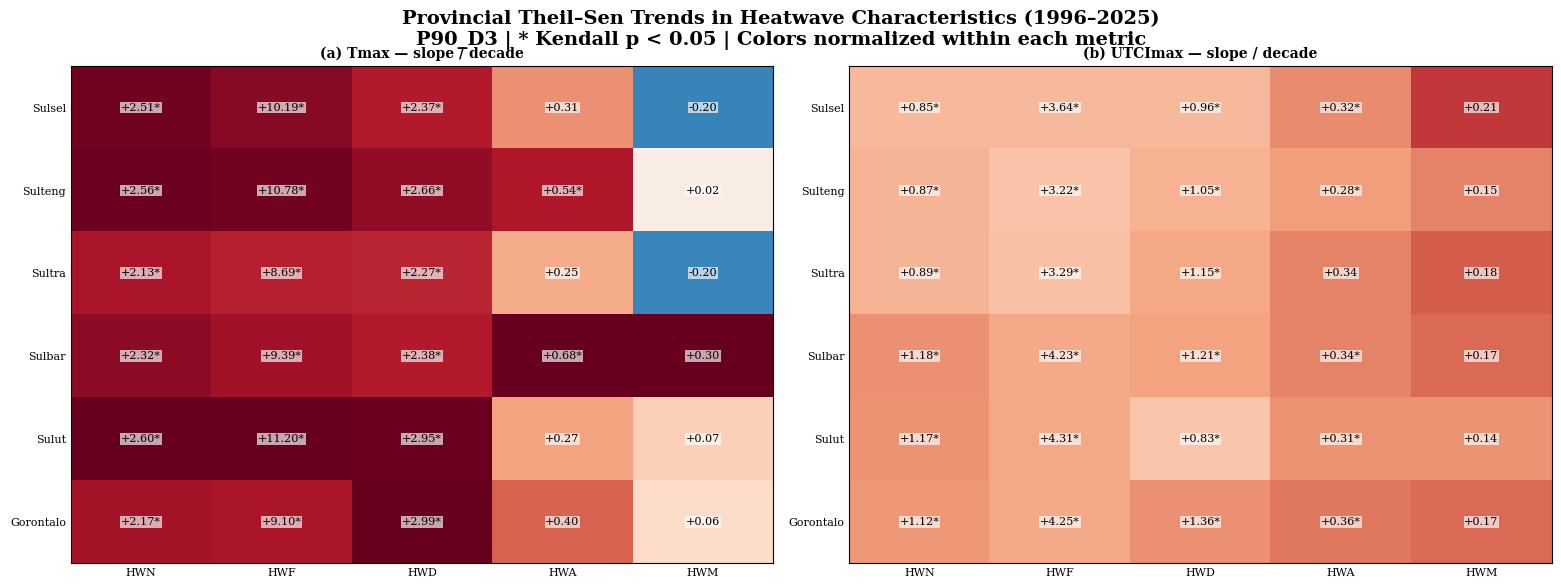

In [39]:
fig, axes=plt.subplots(1,2,figsize=(15.5,5.4),constrained_layout=True)
# Normalisasi per-metrik: hindari menyamakan skala tren HWF (hari) dengan HWA (°C).
metric_scale = {}
for metric in METRIC_CODES:
    data_m = trend_df.loc[trend_df.metric == metric, 'slope_decade'].to_numpy(dtype=float)
    metric_scale[metric] = max(1e-6, float(np.nanmax(np.abs(data_m)))) if np.isfinite(data_m).any() else 1.0
for ax,basis in zip(axes,['Tmax','UTCImax']):
    data=np.array([[trend_df.query('province == @prov and basis == @basis and metric == @metric').slope_decade.iloc[0]
                    for metric in METRIC_CODES] for prov in province_order])
    normalized = np.column_stack([data[:, k] / metric_scale[m] for k, m in enumerate(METRIC_CODES)])
    ax.imshow(np.ma.masked_invalid(normalized),cmap='RdBu_r',vmin=-1,vmax=1,aspect='auto')
    ax.set_xticks(np.arange(len(METRIC_CODES)),METRIC_CODES)
    ax.set_yticks(np.arange(len(province_order)),[province_short[p] for p in province_order])
    for ii,p in enumerate(province_order):
        for jj,m in enumerate(METRIC_CODES):
            row=trend_df.query('province == @p and basis == @basis and metric == @m').iloc[0]
            s=('NA' if not np.isfinite(row.slope_decade) else f'{row.slope_decade:+.2f}' + ('*' if row.significant_0_05 else ''))
            ax.text(jj,ii,s,ha='center',va='center',fontsize=8.1,color='black',bbox=dict(facecolor='white',alpha=.65,edgecolor='none',pad=.6))
    ax.set_title(f'({"a" if basis=="Tmax" else "b"}) {basis} — slope / decade',weight='bold')
    ax.tick_params(length=0)
fig.suptitle(f'Provincial Theil–Sen Trends in Heatwave Characteristics ({START_YEAR}–{END_YEAR})\n{MAIN_SCENARIO} | * Kendall p < 0.05 | Colors normalized within each metric',weight='bold',y=1.06)
op=PLOT_DIR/f'FIG05_Provincial_Trend_Matrix_{MAIN_SCENARIO}.png'
fig.savefig(op,dpi=FIG_DPI,bbox_inches='tight')
if SAVE_PDF:fig.savefig(op.with_suffix('.pdf'),bbox_inches='tight')
plt.show();plt.close(fig)

## Figures 6a–6e — Peta tiga panel smooth: Tmax / UTCImax / selisih
**Setiap metrik menghasilkan satu peta.** Panel (a) dan (b) memakai color scale sama; panel selisih (c) hanya untuk HWN, HWF, HWD. HWA/HWM ditampilkan sebagai dua panel tanpa pengurangan nilai karena UTCI adalah temperatur ekuivalen, bukan suhu udara. Interpolasi **linear hanya pada gambar**, tidak mengubah nilai per grid, tren atau perhitungan deteksi heatwave. Mask mengikuti footprint pusat-grid observasi dan gabungan enam batas provinsi (Natural Earth 10m). Peta smooth dapat memperlihatkan transisi antargrid; **bukan bukti detail resolusi lebih tinggi**.

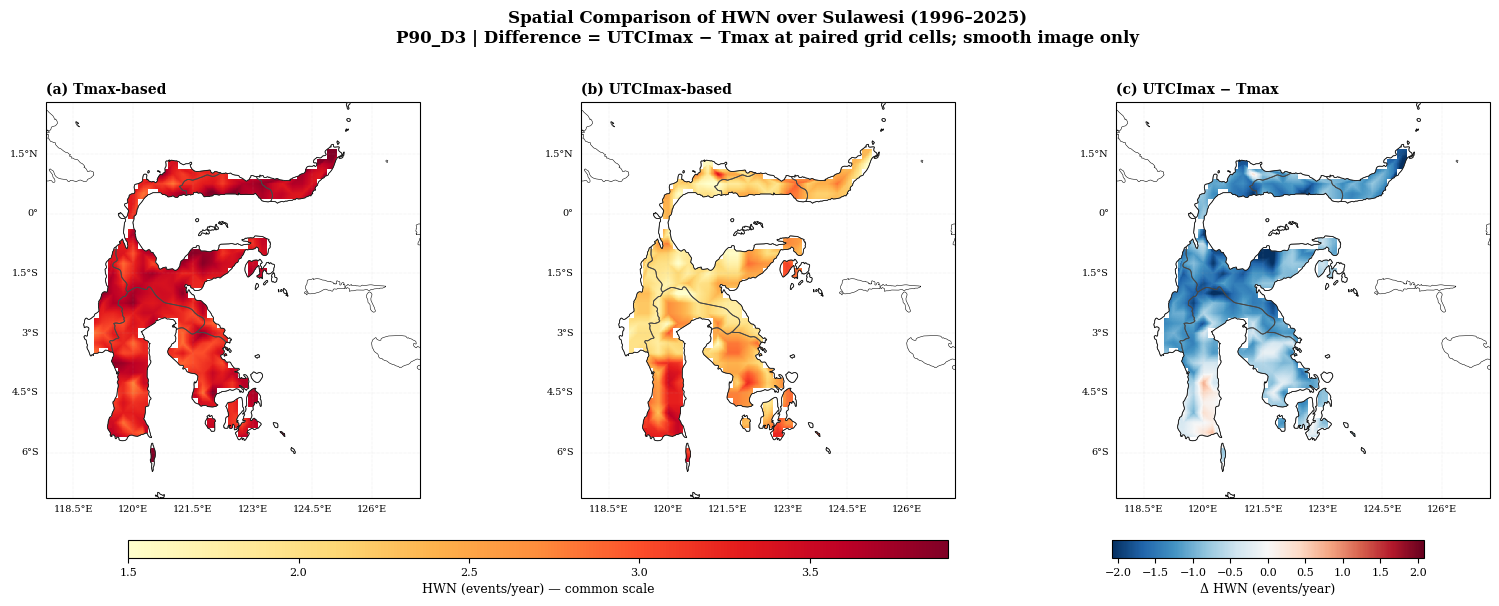

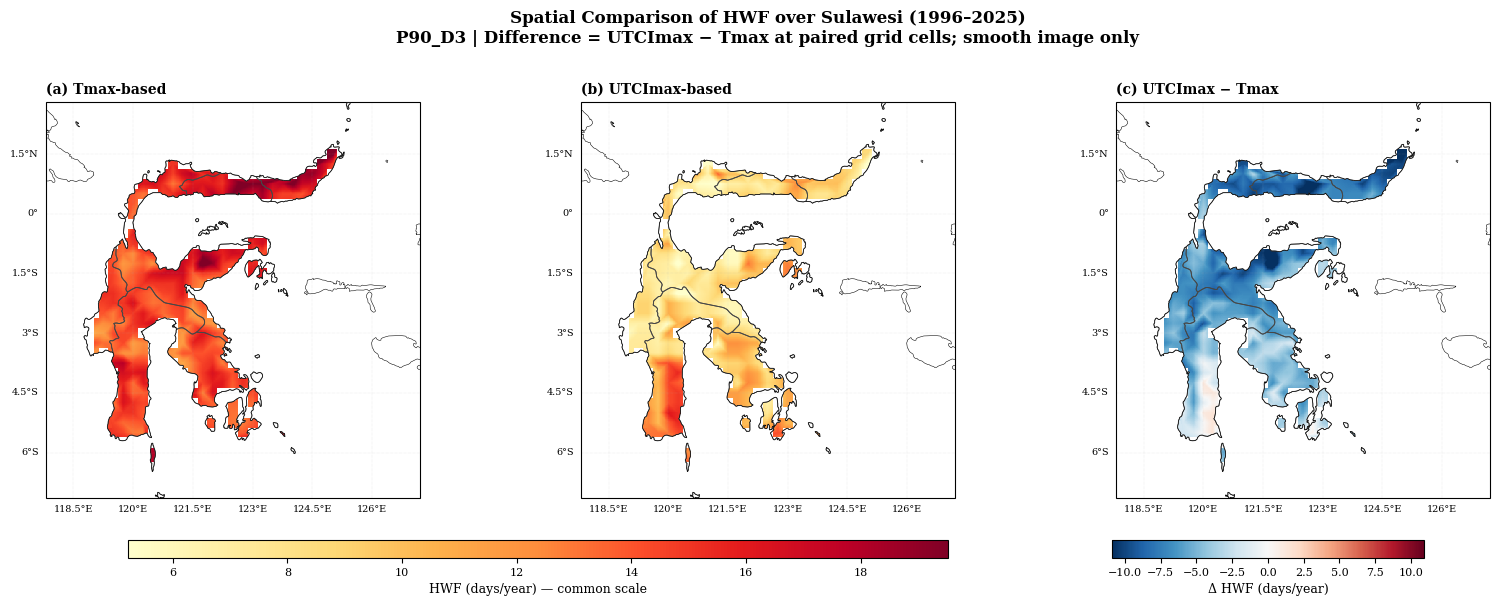

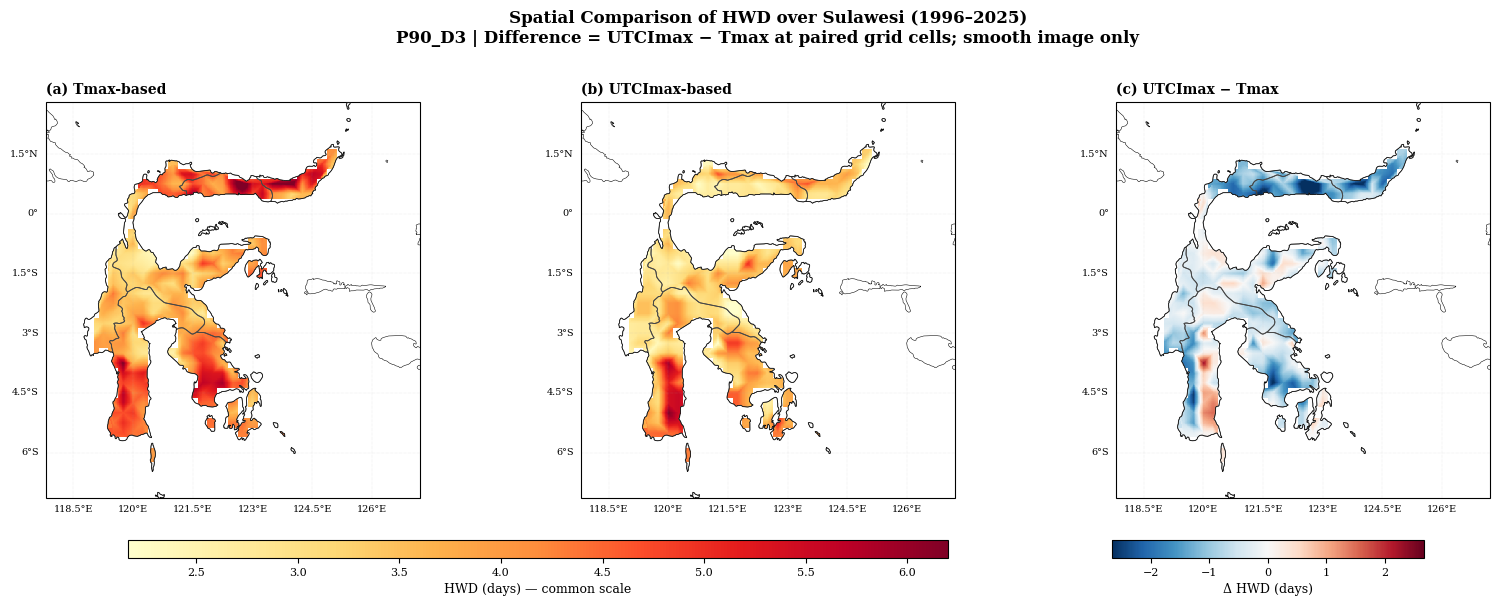

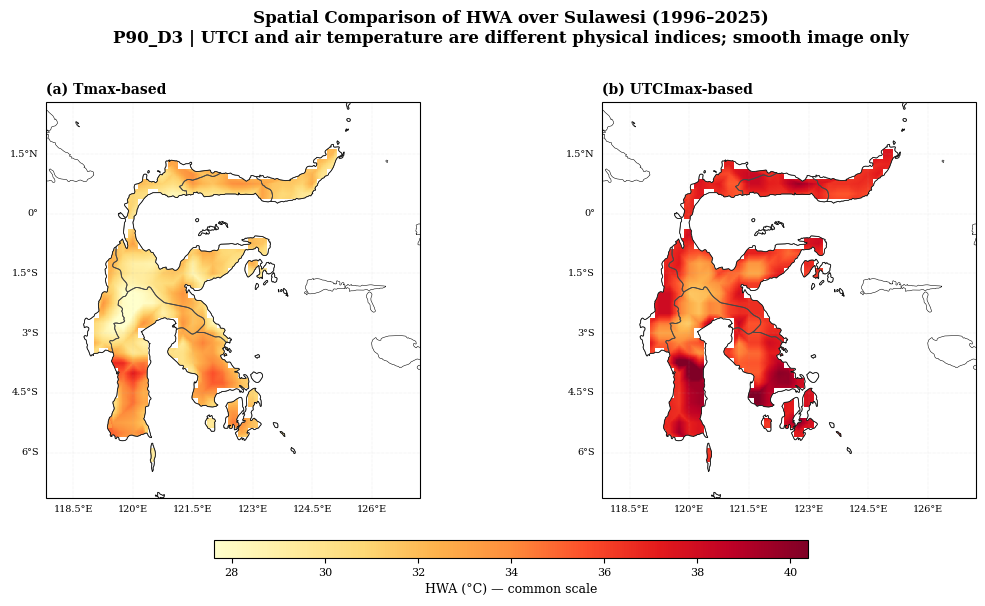

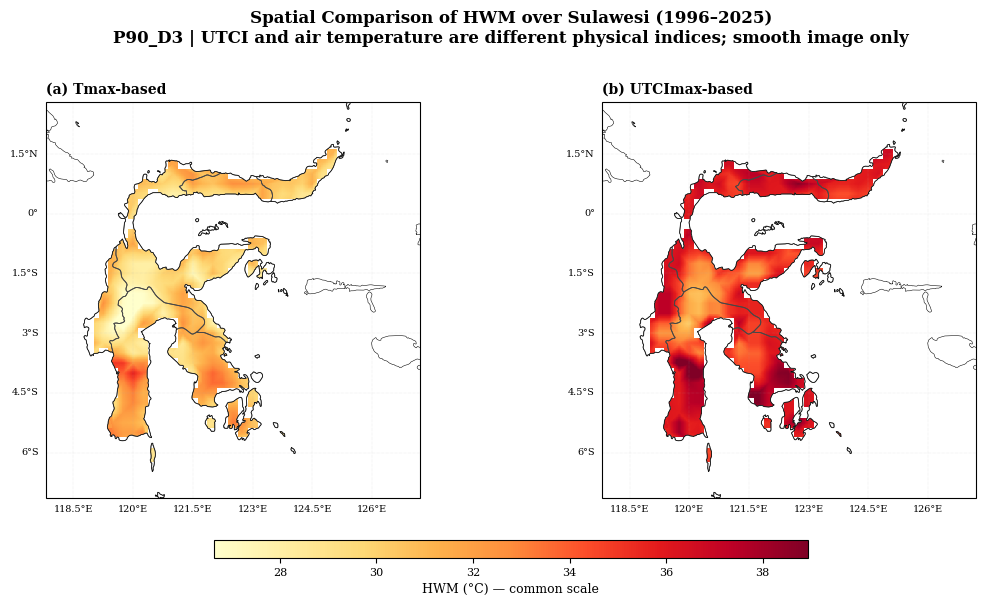

In [40]:
# Batas provinsi dan gabungan geometri. Hanya dari enam provinsi yang sudah dimuat di sel KDE.
all_province_geoms = {p:unary_union(province_geometries[p]) for p in province_order}
land_geometry=unary_union(list(all_province_geoms.values()))
try:
    from shapely import contains_xy as contains_xy_func
except ImportError:
    from shapely.vectorized import contains as contains_xy_func

_fine_cache=None
def fine_canvas():
    global _fine_cache
    if _fine_cache is None:
        gx=np.linspace(MAP_EXTENT[0],MAP_EXTENT[1],DISPLAY_NX)
        gy=np.linspace(MAP_EXTENT[2],MAP_EXTENT[3],DISPLAY_NY)
        xx,yy=np.meshgrid(gx,gy)
        # little edge buffer to preserve coastal boundary
        land=np.asarray(contains_xy_func(land_geometry.buffer(1e-8),xx,yy),dtype=bool)
        _fine_cache=(gx,gy,xx,yy,land)
    return _fine_cache

def smooth_field(field):
    """Interpolate continuous variable for image only; crop to native support and province polygons."""
    z=np.asarray(field,dtype=float).copy()
    z[~province_union_mask]=np.nan
    good=np.isfinite(z)
    if good.sum()<4: raise ValueError('Peta butuh >=4 grid valid.')
    gx,gy,xx,yy,land=fine_canvas()
    lxx,lyy=np.meshgrid(cmp_lon,cmp_lat)
    points=np.column_stack((lxx[good],lyy[good]))
    out=griddata(points,z[good],(xx,yy),method='linear')
    holes=land & ~np.isfinite(out)
    if holes.any():
        nn=griddata(points,z[good],(xx,yy),method='nearest')
        out[holes]=nn[holes]
    # Native nearest-center footprint; cannot bridge missing grid cells or ocean.
    f=RegularGridInterpolator((cmp_lat,cmp_lon),good.astype(np.float32),method='nearest',bounds_error=False,fill_value=0.0)
    supported=f(np.column_stack([yy.ravel(),xx.ravel()])).reshape(xx.shape)>=.5
    out[~(land&supported)]=np.nan
    return gx,gy,out

def draw_metric(ax,z,cmap,vmin,vmax):
    z=np.asarray(z,dtype=float)
    cm=mpl.colormaps[cmap].copy();cm.set_bad((1,1,1,0))
    if DISPLAY_RENDER=='smooth':
        xx,yy,zz=smooth_field(z)
        image=ax.pcolormesh(xx,yy,np.ma.masked_invalid(zz),cmap=cm,vmin=vmin,vmax=vmax,shading='auto',transform=ccrs.PlateCarree(),rasterized=True,zorder=2)
    elif DISPLAY_RENDER=='native':
        zz=np.where(province_union_mask,z,np.nan)
        image=ax.pcolormesh(cmp_lon,cmp_lat,np.ma.masked_invalid(zz),cmap=cm,vmin=vmin,vmax=vmax,shading='nearest',transform=ccrs.PlateCarree(),rasterized=True,zorder=2)
    else: raise ValueError('DISPLAY_RENDER harus smooth / native')
    for geom in all_province_geoms.values():
        ax.add_geometries([geom],crs=ccrs.PlateCarree(),facecolor='none',edgecolor='0.28',lw=.65,zorder=4)
    ax.coastlines(resolution='10m',linewidth=.38,zorder=4)
    ax.set_extent(MAP_EXTENT,crs=ccrs.PlateCarree())
    gl=ax.gridlines(draw_labels=True,linestyle=':',linewidth=.35,alpha=.45)
    gl.top_labels=False;gl.right_labels=False
    gl.xlabel_style={'size':7};gl.ylabel_style={'size':7}
    return image

def cmap_limits(*arrs,difference=False):
    vec=np.concatenate([np.asarray(a)[np.isfinite(a)].ravel() for a in arrs if np.isfinite(a).any()])
    if vec.size==0: return (-1.,1.) if difference else (0.,1.)
    if difference:
        mx=np.percentile(np.abs(vec),98)
        return (-float(mx) if mx>0 else -1.,float(mx) if mx>0 else 1.)
    low=max(0.,float(np.percentile(vec,1))) if (vec>=0).all() else float(np.percentile(vec,1))
    high=float(np.percentile(vec,99))
    return (low,high if high>low else low+1.)

for metric in METRIC_CODES:
    tval=np.nanmean(annual_fields['Tmax'][metric],axis=0)
    uval=np.nanmean(annual_fields['UTCImax'][metric],axis=0)
    tval=np.where(province_union_mask,tval,np.nan)
    uval=np.where(province_union_mask,uval,np.nan)
    vmin,vmax=cmap_limits(tval,uval)
    # HWA/HWM adalah nilai indeks absolut dengan makna fisik berbeda.
    # Jangan hitung UTCI minus Tmax untuk kedua intensitas itu.
    has_diff = metric in ('HWN','HWF','HWD')
    ncols=3 if has_diff else 2
    fig,axs=plt.subplots(1,ncols,figsize=(16.4 if has_diff else 11.0,6.6),
                         subplot_kw={'projection':ccrs.PlateCarree()})
    im1=draw_metric(axs[0],tval,'YlOrRd',vmin,vmax)
    draw_metric(axs[1],uval,'YlOrRd',vmin,vmax)
    labels=['Tmax-based','UTCImax-based']
    if has_diff:
        diff=np.where(np.isfinite(tval)&np.isfinite(uval),uval-tval,np.nan)
        dm,dx=cmap_limits(diff,difference=True)
        im3=draw_metric(axs[2],diff,'RdBu_r',dm,dx)
        labels.append('UTCImax − Tmax')
    for i,(ax,cap) in enumerate(zip(axs,labels)):
        ax.set_title(f'({chr(97+i)}) {cap}',loc='left',weight='bold',fontsize=10)
    fig.subplots_adjust(left=.04,right=.96,bottom=.22,top=.82,wspace=.22)
    if has_diff:
        c1=fig.add_axes([.11,.13,.50,.027])
        c2=fig.add_axes([.71,.13,.19,.027])
        cb=fig.colorbar(im3,cax=c2,orientation='horizontal')
        cb.set_label(f'Δ {metric} ({METRIC_UNIT[metric]})',fontsize=9)
    else:
        c1=fig.add_axes([.23,.13,.54,.027])
    cb=fig.colorbar(im1,cax=c1,orientation='horizontal')
    cb.set_label(f'{metric} ({METRIC_UNIT[metric]}) — common scale',fontsize=9)
    detail=('UTCI and air temperature are different physical indices'
            if not has_diff else 'Difference = UTCImax − Tmax at paired grid cells')
    fig.suptitle(f'Spatial Comparison of {metric} over Sulawesi ({START_YEAR}–{END_YEAR})\n'
                 f'{MAIN_SCENARIO} | {detail}; {DISPLAY_RENDER} image only',fontsize=12,weight='bold',y=.96)
    op=PLOT_DIR/f'FIG06_{metric}_Spatial_Tmax_UTCI_Comparison_{DISPLAY_RENDER}_{MAIN_SCENARIO}.png'
    fig.savefig(op,dpi=FIG_DPI,bbox_inches='tight',facecolor='white')
    if SAVE_PDF:fig.savefig(op.with_suffix('.pdf'),bbox_inches='tight',facecolor='white')
    plt.show();plt.close(fig)


## 7. Deteksi harian untuk studi kasus & pola bulanan (seperti notebook CaseStudy)
Hanya menghitung event mask untuk keperluan grafik kasus dan sebaran bulan. **Deteksi diulang terpisah per tahun kalender**, persis pola pengolahan notebook Tmax/UTCI Combined. Berlaku mask masing-masing indeks pada grid asli; perhitungan kategori “both / only” menggunakan validitas data kedua indeks pada hari yang sama. **Binary event map tidak dihaluskan** karena interpolasi pada kelas ya/tidak akan menyesatkan.

In [41]:
# Implementasi run-length yang sama dengan notebook sumber: dua-pass, tahunan.
def event_mask_from_daily(exceed, minimum):
    exceed=np.asarray(exceed,dtype=bool)
    end_run=np.zeros(exceed.shape,dtype=np.int16)
    run=np.zeros(exceed.shape[1:],dtype=np.int16)
    for t in range(len(exceed)):
        run=np.where(exceed[t],run+1,0).astype(np.int16)
        end_run[t]=run
    out=np.zeros(exceed.shape,dtype=bool)
    run=np.zeros(exceed.shape[1:],dtype=np.int16)
    for t in range(len(exceed)-1,-1,-1):
        run=np.where(exceed[t],run+1,0).astype(np.int16)
        out[t]=exceed[t]&((end_run[t]+run-1)>=minimum)
    return out

all_years=all_dates.year.to_numpy()
tmax_hw=np.zeros(tmax_values_cmp.shape,dtype=bool)
utci_hw=np.zeros(utci_values_cmp.shape,dtype=bool)
for year in YEARS:
    select=np.where(all_years==year)[0]
    vt=np.asarray(tmax_values_cmp[select],dtype=np.float32)
    vu=np.asarray(utci_values_cmp[select],dtype=np.float32)
    rt=tmax_thr_daily[select];ru=utci_thr_daily[select]
    tmax_hw[select]=event_mask_from_daily(np.isfinite(vt)&np.isfinite(rt)&(vt>rt),MIN_DURATION)
    utci_hw[select]=event_mask_from_daily(np.isfinite(vu)&np.isfinite(ru)&(vu>ru),MIN_DURATION)

# Tak perlu konstruksi common_valid_3d agar tidak menggandakan memori; province mask sudah common-grid.
mask_shared=(np.isfinite(tmax_values_cmp)&np.isfinite(utci_values_cmp)&
             np.isfinite(tmax_thr_daily)&np.isfinite(utci_thr_daily))

def province_area_pct(mask3d,prov_mask):
    w=np.where(prov_mask,weights2d,0.)
    denom=np.sum(w)
    if denom<=0: return np.full(mask3d.shape[0],np.nan)
    return 100*np.einsum('tij,ij->t',mask3d.astype(float),w,optimize=True)/denom

# Time series per province for each category, with fully common valid daily support for agreement.
prov_daily={}
for prov in province_order:
    mask=province_masks[prov]
    available=mask_shared & mask[None,:,:]
    t=tmax_hw & available
    u=utci_hw & available
    prov_daily[prov]={
        'Tmax':province_area_pct(t,mask), 'UTCImax':province_area_pct(u,mask),
        'Both':province_area_pct(t&u,mask),
        'Tmax_only':province_area_pct(t&~u,mask),
        'UTCI_only':province_area_pct(u&~t,mask),
        'coverage':province_area_pct(available,mask)
    }

# Auto case selection: province-pooled *coverage-weighted* overlap score in time.
combined_mask=province_union_mask
regional_t=province_area_pct(tmax_hw & mask_shared,combined_mask)
regional_u=province_area_pct(utci_hw & mask_shared,combined_mask)
regional_both=province_area_pct(tmax_hw & utci_hw & mask_shared,combined_mask)
if CASE_SELECTION=='overlap':
    score=2*regional_both + np.minimum(regional_t,regional_u)
elif CASE_SELECTION=='contrast': score=np.abs(regional_t-regional_u)
elif CASE_SELECTION=='tmax': score=regional_t
elif CASE_SELECTION=='utci': score=regional_u
else: raise ValueError('CASE_SELECTION harus overlap / contrast / tmax / utci')
score_smoothed=pd.Series(score,index=all_dates).rolling(CASE_SMOOTH_DAYS,center=True,min_periods=1).mean()
center=score_smoothed.idxmax() if AUTO_CASE else pd.Timestamp(CASE_CENTER)
if center not in score_smoothed.index: raise ValueError('CASE_CENTER tidak ditemukan di time axis.')
idx_center=int(np.where(all_dates==center)[0][0])
start=max(0,idx_center-CASE_HALF_WINDOW_DAYS)
stop=min(len(all_dates),idx_center+CASE_HALF_WINDOW_DAYS+1)
case_days=all_dates[start:stop]
case_df=pd.DataFrame({'date':case_days})
for p in province_order:
    for stat,y in prov_daily[p].items():
        case_df[f'{province_short[p]}_{stat}_pct']=y[start:stop]
case_df.to_csv(TABLE_DIR/f'TABLE04_CaseStudy_Provincial_{center.strftime("%Y%m%d")}.csv',index=False)
print('Case-study selected:',center.date(), '| interval:',case_days[0].date(),case_days[-1].date())

Case-study selected: 2013-06-21 | interval: 2013-06-11 2013-07-01


## Figure 7 — Studi kasus tumpang tindih Tmax–UTCI per provinsi
**Enam panel per provinsi** untuk satu periode dipilih secara otomatis; satuan % dari seluruh grid daratan provinsi pada common grid (bukan % penduduk). Garis “both” menyatakan kejadian yang sama-sama teridentifikasi pada hari dan grid identik.

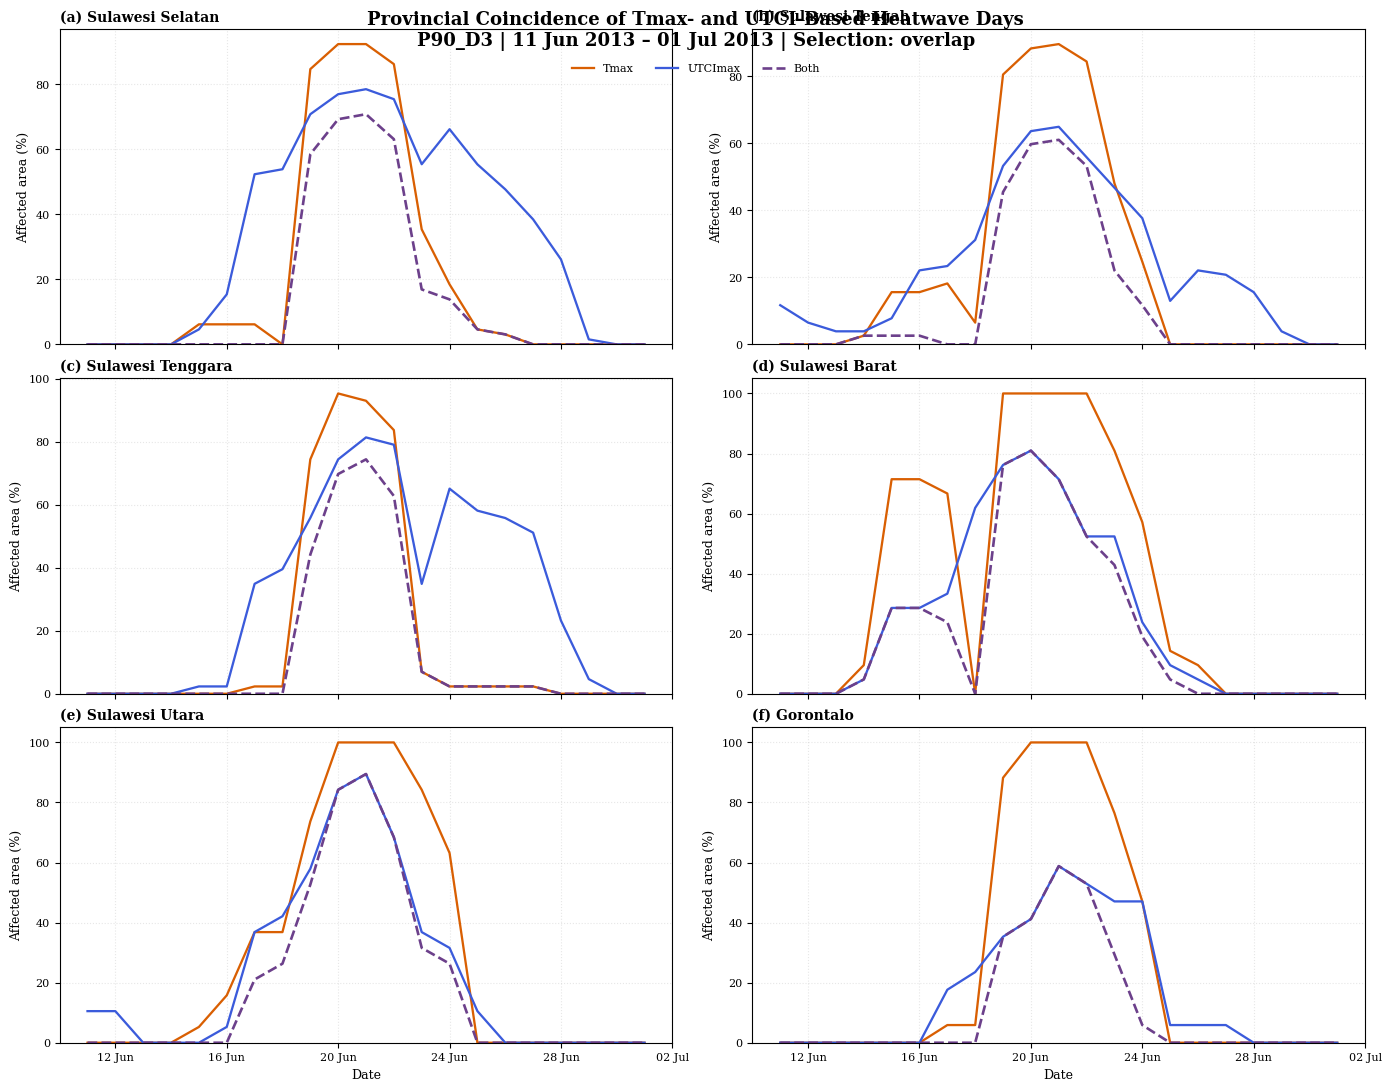

In [42]:
fig,axs=plt.subplots(3,2,figsize=(13.8,10.8),sharex=True,constrained_layout=True)
for i,p in enumerate(province_order):
    ax=axs.flat[i]
    for typ,col,sty,lw in [('Tmax',TMAX_COLOR,'-',1.65),('UTCImax',UTCI_COLOR,'-',1.65),('Both','#6c408b','--',1.9)]:
        ax.plot(case_days,prov_daily[p][typ][start:stop],color=col,ls=sty,lw=lw,label=typ)
    ax.set_title(f'({chr(97+i)}) {p}',loc='left',fontweight='bold')
    ax.set_ylabel('Affected area (%)')
    ax.set_ylim(bottom=0);ax.grid(ls=':',alpha=.3)
    ax.xaxis.set_major_locator(mdates.DayLocator(interval=4))
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%d %b'))
for ax in axs[-1]:ax.set_xlabel('Date')
h,l=axs.flat[0].get_legend_handles_labels()
fig.legend(h,l,loc='upper center',bbox_to_anchor=(.5,.955),ncol=3,frameon=False)
fig.suptitle(f'Provincial Coincidence of Tmax- and UTCI-Based Heatwave Days\n{MAIN_SCENARIO} | {case_days[0].strftime("%d %b %Y")} – {case_days[-1].strftime("%d %b %Y")} | Selection: {CASE_SELECTION}',weight='bold',y=.995,fontsize=13)
op=PLOT_DIR/f'FIG07_Case_Overlap_By_Province_{MAIN_SCENARIO}_{center.strftime("%Y%m%d")}.png'
fig.savefig(op,dpi=FIG_DPI,bbox_inches='tight')
if SAVE_PDF:fig.savefig(op.with_suffix('.pdf'),bbox_inches='tight')
plt.show();plt.close(fig)

## Figure 8 — Siklus bulanan HWF setiap provinsi
Jumlah grid-hari yang memenuhi kejadian dikelompokkan per bulan dan dirata-ratakan **per tahun** pada setiap grid dengan bobot `cos(latitude)`. **Heatwave yang melintasi batas bulan** dihitung menurut hari di bulan tersebut; analisis event tetap memakai persistensi harian minimum di tahun kalender.

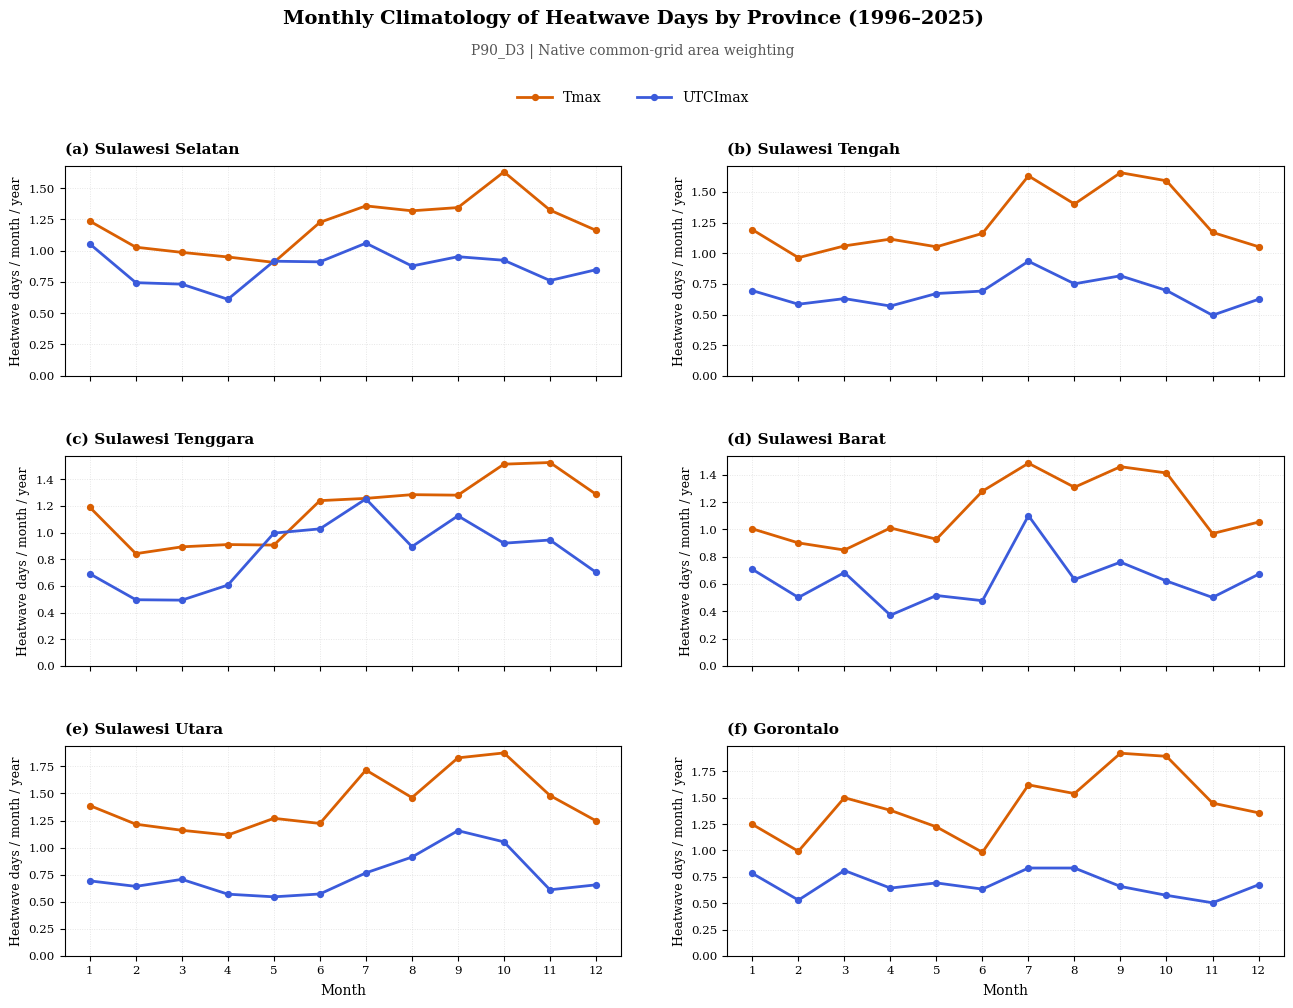

Figure tersimpan: D:\MERLI\data\TMAX_UTCI_COMPARISON\Provincial_Journal_Integrated\plots\FIG08_Monthly_HWF_Six_Provinces_P90_D3.png


In [43]:

# ============================================================
# FIGURE 08 — MONTHLY CLIMATOLOGY OF HEATWAVE DAYS
# Tmax vs UTCImax | Six Provinces of Sulawesi | Journal Style
# ============================================================

monthly_rows = []

for prov in province_order:
    for basis, events in [('Tmax', tmax_hw), ('UTCImax', utci_hw)]:
        region = province_masks[prov]

        for month in range(1, 13):
            vals = []

            for year in YEARS:
                idx = (all_dates.year == year) & (all_dates.month == month)
                annual_month_days = np.sum(
                    events[idx], axis=0, dtype=float
                )[None]

                vals.append(
                    weighted_mean_grids(annual_month_days, region)[0]
                )

            monthly_rows.append({
                'province': prov,
                'basis': basis,
                'month': month,
                'avg_monthly_hw_days_per_year': np.nanmean(vals)
            })

monthly_df = pd.DataFrame(monthly_rows)

monthly_df.to_csv(
    TABLE_DIR / f'TABLE05_Monthly_Provincial_HWF_{MAIN_SCENARIO}.csv',
    index=False
)

# ============================================================
# PENGATURAN FIGURE
# ============================================================

fig, axs = plt.subplots(
    3, 2,
    figsize=(13.7, 10.4),
    sharex=True
)

# Sediakan area khusus untuk judul, subtitle, dan legenda
fig.subplots_adjust(
    left=0.085,
    right=0.975,
    bottom=0.075,
    top=0.835,
    hspace=0.38,
    wspace=0.19
)

# ============================================================
# PLOT SETIAP PROVINSI
# ============================================================

for i, p in enumerate(province_order):
    ax = axs.flat[i]

    for basis, color in [
        ('Tmax', TMAX_COLOR),
        ('UTCImax', UTCI_COLOR)
    ]:
        sel = monthly_df[
            (monthly_df.province == p) &
            (monthly_df.basis == basis)
        ].sort_values('month')

        ax.plot(
            sel.month,
            sel.avg_monthly_hw_days_per_year,
            color=color,
            lw=2.0,
            marker='o',
            ms=4.2,
            label=basis,
            zorder=3
        )

    ax.set_title(
        f'({chr(97+i)}) {p}',
        loc='left',
        fontsize=11,
        fontweight='bold',
        pad=9
    )

    ax.set_ylim(bottom=0)
    ax.set_ylabel(
        'Heatwave days / month / year',
        fontsize=9
    )

    ax.set_xticks(range(1, 13))
    ax.tick_params(axis='both', labelsize=8.5)

    ax.grid(
        True,
        linestyle=':',
        linewidth=0.65,
        alpha=0.35,
        zorder=0
    )

    ax.spines['top'].set_linewidth(0.8)
    ax.spines['right'].set_linewidth(0.8)

# Label bulan pada baris terakhir
for ax in axs[-1]:
    ax.set_xlabel('Month', fontsize=10, labelpad=6)

# ============================================================
# JUDUL UTAMA — TERPISAH DARI PANEL
# ============================================================

fig.suptitle(
    'Monthly Climatology of Heatwave Days by Province '
    f'({START_YEAR}–{END_YEAR})',
    fontsize=14,
    fontweight='bold',
    y=0.985
)

# Subtitle
fig.text(
    0.5,
    0.945,
    f'{MAIN_SCENARIO} | Native common-grid area weighting',
    ha='center',
    va='center',
    fontsize=10,
    color='#555555'
)

# ============================================================
# LEGENDA GLOBAL — DI BAWAH SUBTITLE
# ============================================================

handles, labels = axs.flat[0].get_legend_handles_labels()

fig.legend(
    handles,
    labels,
    loc='upper center',
    bbox_to_anchor=(0.5, 0.919),
    ncol=2,
    frameon=False,
    fontsize=10,
    handlelength=2.5,
    columnspacing=2.5
)

# ============================================================
# SIMPAN FIGURE
# ============================================================

op = PLOT_DIR / (
    f'FIG08_Monthly_HWF_Six_Provinces_{MAIN_SCENARIO}.png'
)

fig.savefig(
    op,
    dpi=FIG_DPI,
    bbox_inches='tight',
    facecolor='white'
)

if SAVE_PDF:
    fig.savefig(
        op.with_suffix('.pdf'),
        bbox_inches='tight',
        facecolor='white'
    )

plt.show()
plt.close(fig)

print(f'Figure tersimpan: {op}')


## 8. Ringkasan otomatis untuk Bab III skripsi — setelah Run All
Buat teks **berdasarkan hasil yang benar-benar terhitung**, bukan mengarang angka. `p < 0,05` dibaca sebagai signifikan untuk pengujian Kendall tanpa koreksi autokorelasi. Klaim tentang perbedaan Tmax dan UTCI tidak berarti beda risiko kesehatan secara langsung.

In [44]:
lines = [
    f'RINGKASAN HASIL PROVINSI SULAWESI {START_YEAR}–{END_YEAR}, DEFINISI {MAIN_SCENARIO}',
    'Data: native ERA5 Tmax dan ERA5-HEAT UTCImax pada pusat grid bersama; wilayah administratif Natural Earth 10m.',
    'Metode: indeks heatwave tahunan dari cache sumber; rerata cos(latitude); Theil–Sen/Kendall.',
    'Interpretasi: HWA/HWM adalah indeks nilai absolut selama hari kejadian; UTCI adalah temperatur ekuivalen.',
    ''
]
for metric in METRIC_CODES:
    lines.append(f'[{metric}]')
    for p in province_order:
        zt=trend_df.query('province == @p and basis == "Tmax" and metric == @metric').iloc[0]
        zu=trend_df.query('province == @p and basis == "UTCImax" and metric == @metric').iloc[0]
        cr=corr_df.query('province == @p and metric == @metric').iloc[0]
        def info(z):
            s=f'{z.mean_1996_2025:.2f} {METRIC_UNIT[metric]}'
            if np.isfinite(z.slope_decade):
                s+=f'; tren {z.slope_decade:+.2f} per dekade (Kendall p={z.kendall_p:.3g})'
            return s
        lines.append(f'- {p}: Tmax {info(zt)}; UTCImax {info(zu)}; r tahunan={cr.pearson_r:.2f}.')
    lines.append('')
lines += [
    'Catatan ilmiah: korelasi antartahun tidak membuktikan episode harian berimpit. Analisis overlap ada pada FIG07.',
    'Persentase area adalah fraksi grid berbobot luas, bukan persentase penduduk atau ukuran dampak kesehatan.',
    'Penggunaan interpolasi linear terbatas pada FIG06 sebagai visualisasi resolusi tinggi; semua nilai statistik asli.',
    'Untuk menyusun Bab III, sebutkan hanya angka, arah tren, dan p yang tercantum pada hasil sebenarnya.'
]
report='\n'.join(lines)
report_path=TABLE_DIR/f'Narasi_Dasar_Hasil_Per_Provinsi_{MAIN_SCENARIO}.txt'
report_path.write_text(report,encoding='utf-8')
print(report[:5500])
# Excel export opsional; CSV selalu tersedia.
try:
    with pd.ExcelWriter(TABLE_DIR/f'Provincial_Results_1996_2025_{MAIN_SCENARIO}.xlsx',engine='openpyxl') as xl:
        coverage_df.to_excel(xl,sheet_name='Data coverage',index=False)
        summary_df.to_excel(xl,sheet_name='KDE summary',index=False)
        prov_annual.to_excel(xl,sheet_name='Annual metrics',index=False)
        trend_df.to_excel(xl,sheet_name='Theil Sen Kendall',index=False)
        corr_df.to_excel(xl,sheet_name='Annual correlation',index=False)
        monthly_df.to_excel(xl,sheet_name='Monthly HWF',index=False)
    print('Workbook tersedia.')
except ImportError:
    print('openpyxl belum terinstal; tabel CSV sudah tetap tersimpan.')

RINGKASAN HASIL PROVINSI SULAWESI 1996–2025, DEFINISI P90_D3
Data: native ERA5 Tmax dan ERA5-HEAT UTCImax pada pusat grid bersama; wilayah administratif Natural Earth 10m.
Metode: indeks heatwave tahunan dari cache sumber; rerata cos(latitude); Theil–Sen/Kendall.
Interpretasi: HWA/HWM adalah indeks nilai absolut selama hari kejadian; UTCI adalah temperatur ekuivalen.

[HWN]
- Sulawesi Selatan: Tmax 3.33 events/year; tren +2.51 per dekade (Kendall p=4.98e-06); UTCImax 2.60 events/year; tren +0.85 per dekade (Kendall p=0.00289); r tahunan=0.56.
- Sulawesi Tengah: Tmax 3.40 events/year; tren +2.56 per dekade (Kendall p=1.36e-05); UTCImax 2.15 events/year; tren +0.87 per dekade (Kendall p=0.00132); r tahunan=0.63.
- Sulawesi Tenggara: Tmax 3.29 events/year; tren +2.13 per dekade (Kendall p=9.99e-05); UTCImax 2.53 events/year; tren +0.89 per dekade (Kendall p=0.00327); r tahunan=0.52.
- Sulawesi Barat: Tmax 3.30 events/year; tren +2.32 per dekade (Kendall p=5.59e-08); UTCImax 2.02 events/ye

## 9. Pemeriksaan output dan keterbatasan
**Sebelum memasukkan gambar ke skripsi:**
1. Lihat angka valid grid/coverage setiap provinsi. Natural Earth Admin-1 punya keterbatasan garis batas; untuk pelaporan administratif resmi, pertimbangkan SHP Dukcapil yang sesuai dan verifikasi seluruh pusat grid.
2. Periksa kemiripan hasil annual metric gabungan dengan pipeline sumber dan peta hasil native vs smooth (`DISPLAY_RENDER='native'` untuk QC).
3. Ingat kernel KDE menunjukkan distribusi **seluruh hari**, sedangkan HWN/HWF/HWD/HWA/HWM dihitung hanya dari **episode ≥3 hari**. Jangan menyamakan “% hari di atas P90” dengan “% hari heatwave”.
4. Perbedaan HWF dan nilai UTCI bukan otomatis ukuran risiko kesehatan; penelitian ini membandingkan indikator atmosfer dan stres termal.
5. Hasil dan gambar akhir belum divalidasi terhadap file NetCDF asli pada komputer pengguna; cek semua gambar setelah menjalankan notebook.

In [45]:
files_png=sorted(PLOT_DIR.glob('FIG*.png'))
files_csv=sorted(TABLE_DIR.glob('TABLE*.csv'))
print(f'Figure PNG: {len(files_png)} (expected 16: 2 KDE + 1 bar + 5 timeseries + 1 trend + 5 maps + 1 case + 1 monthly)')
for f in files_png: print('  ',f.name)
print('\nTabel CSV:',len(files_csv))
for f in files_csv: print('  ',f.name)
print('\nOutput folder:',OUTPUT_DIR)
print('Selesai — hasil siap diperiksa sebelum dipakai dalam skripsi.')

Figure PNG: 16 (expected 16: 2 KDE + 1 bar + 5 timeseries + 1 trend + 5 maps + 1 case + 1 monthly)
   FIG01_Provincial_KDE_Absolute_Tmax_UTCImax_P90.png
   FIG02_Provincial_KDE_ThresholdRelative_Tmax_UTCImax_P90.png
   FIG03_Provincial_Climatology_Five_Metrics_P90_D3.png
   FIG04_HWA_Six_Province_Timeseries_P90_D3.png
   FIG04_HWD_Six_Province_Timeseries_P90_D3.png
   FIG04_HWF_Six_Province_Timeseries_P90_D3.png
   FIG04_HWM_Six_Province_Timeseries_P90_D3.png
   FIG04_HWN_Six_Province_Timeseries_P90_D3.png
   FIG05_Provincial_Trend_Matrix_P90_D3.png
   FIG06_HWA_Spatial_Tmax_UTCI_Comparison_smooth_P90_D3.png
   FIG06_HWD_Spatial_Tmax_UTCI_Comparison_smooth_P90_D3.png
   FIG06_HWF_Spatial_Tmax_UTCI_Comparison_smooth_P90_D3.png
   FIG06_HWM_Spatial_Tmax_UTCI_Comparison_smooth_P90_D3.png
   FIG06_HWN_Spatial_Tmax_UTCI_Comparison_smooth_P90_D3.png
   FIG07_Case_Overlap_By_Province_P90_D3_20130621.png
   FIG08_Monthly_HWF_Six_Provinces_P90_D3.png

Tabel CSV: 6
   TABLE00_Coverage_By_Provinc